# 01. Exploratory Data Analysis (EDA)

**Proyek akhir Jaringan Saraf Tiruan: MLP dengan backpropagation**

Tujuan notebook ini adalah memahami pola data sebelum merancang preprocessing dan eksperimen MLP. Pertanyaan yang dijawab:

- Bagaimana distribusi target dan fitur?
- Fitur mana yang berhubungan kuat dengan SOH, dan mana yang redundan?
- Bagaimana pola missing value dan outlier?
- Apakah data cocok untuk input berbasis timesteps?

Analisis hanya memakai **34.929 observasi dari 1.820 baterai train**. Validation dan test tidak disentuh, dan belum ada preprocessing yang di-fit.

## 1. Aturan analisis

- Satu baris adalah satu observasi. Satu baterai bisa punya banyak baris, jadi 34.929 baris bukan 34.929 baterai independen.
- Hash CSV, manifest split, dan kontrak fitur diverifikasi sebelum analisis.
- Missing value tidak diimputasi untuk menghitung statistik.
- Semua korelasi dan perbandingan bersifat deskriptif, bukan bukti sebab akibat.

Seluruh tabel dan gambar disimpan di `results/eda/`. Logika analisis ada di `src/ev_battery/eda.py`.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()), None)
if REPO is None:
    raise RuntimeError("Buka notebook dari root proyek atau folder notebooks.")
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))
ROOT = REPO
from ev_battery.eda import run_eda, TARGET, AGE_LABELS, CHEMISTRIES, weighted_quantile

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.precision", 3)
eda = run_eda(ROOT)
train = eda["train"]
d = eda["analysis"]
t = eda["tables"]
contract = eda["contract"]


def show(name, width=1050):
    display(Image(filename=str(eda["output"] / name), width=width))


print(f"Train saja: {len(train):,} baris dari {train.battery_id.nunique():,} baterai.")
print("Tidak ada model atau preprocessing yang di-fit.")

Train saja: 34,929 baris dari 1,820 baterai.
Tidak ada model atau preprocessing yang di-fit.


### Cakupan kolom

Ke-35 kolom didokumentasikan beserta perannya. Kolom ID, tanggal, dan target alternatif ikut dieksplorasi untuk memahami dataset, tetapi bukan input model.

In [2]:
display(
    t["column_coverage"][
        ["column", "dtype", "unit", "analysis_role", "missing_train", "unique_train_non_null"]
    ]
)
assert len(t["column_coverage"]) == 35
assert set(t["column_coverage"]["column"]) == set(train.columns)

,column,dtype,unit,analysis_role,missing_train,unique_train_non_null
0,battery_id,string,-,excluded,0,1820
1,observation_id,string,-,excluded,0,34929
2,chemistry,categorical,-,primary,2405,4
3,manufacturer,categorical,-,primary,1765,8
4,vehicle_model,categorical,-,primary,2413,8
5,pack_capacity_kwh,float,kWh,primary,1584,550
6,manufacture_date,date,YYYY-MM-DD,excluded,1356,1225
7,observation_date,date,YYYY-MM-DD,excluded,1581,2064
8,battery_age_days,int,days,primary,2115,2064
9,cycle_count,int,cycles,primary,1592,2768


## 2. Distribusi target

Histogram dan ECDF menunjukkan rentang SOH mana yang paling banyak terwakili. Garis 80% adalah batas end-of-life menurut dokumentasi sumber.

,SOH (%)
count,34929.000
mean,92.919
std,7.193
min,55.000
1%,67.256
5%,78.220
25%,90.080
50%,95.230
75%,98.050
95%,99.940


,nilai
SOH >=95% (persen observasi),51.622
SOH <80% (persen observasi),6.361
tepat 100% (baris),1603.000
tepat 55% (baris),80.000


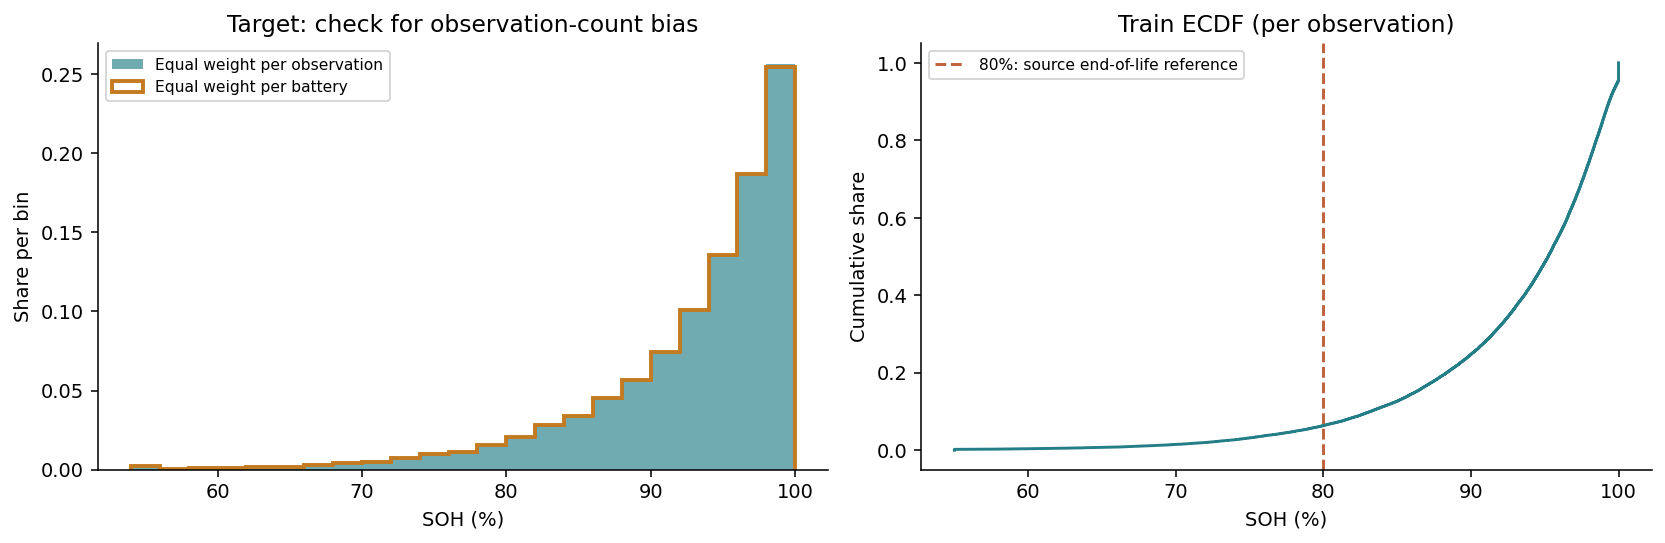

In [3]:
target = train[TARGET]
summary = target.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("SOH (%)")
display(summary)
display(
    pd.Series(
        {
            "SOH >=95% (persen observasi)": target.ge(95).mean() * 100,
            "SOH <80% (persen observasi)": target.lt(80).mean() * 100,
            "tepat 100% (baris)": target.eq(100).sum(),
            "tepat 55% (baris)": target.eq(55).sum(),
        }
    ).to_frame("nilai")
)
show("01_target_and_weighting.png")

**Temuan:** median SOH 95,23% dan rerata 92,92%. Sekitar 51,62% observasi memiliki SOH ≥95%, sedangkan hanya 6,36% di bawah 80%. Distribusinya miring ke kiri dengan ekor ke arah SOH rendah.

**Implikasi:** MAE keseluruhan bisa menyembunyikan error besar pada SOH rendah, jadi evaluasi perlu melaporkan error per rentang SOH. Balancing kelas seperti SMOTE tidak relevan karena targetnya kontinu (regresi).

## 3. Apakah baterai dengan banyak observasi mendominasi?

Distribusi dihitung dua kali: bobot sama per observasi dan bobot sama per baterai (setiap baris diberi bobot 1/jumlah observasi baterainya).

,nilai
mean_per_observasi,92.919
mean_bobot_sama_per_baterai,92.913
median_per_observasi,95.230
median_bobot_sama_per_baterai,95.210
spearman_jumlah_observasi_vs_mean_soh_baterai,0.014


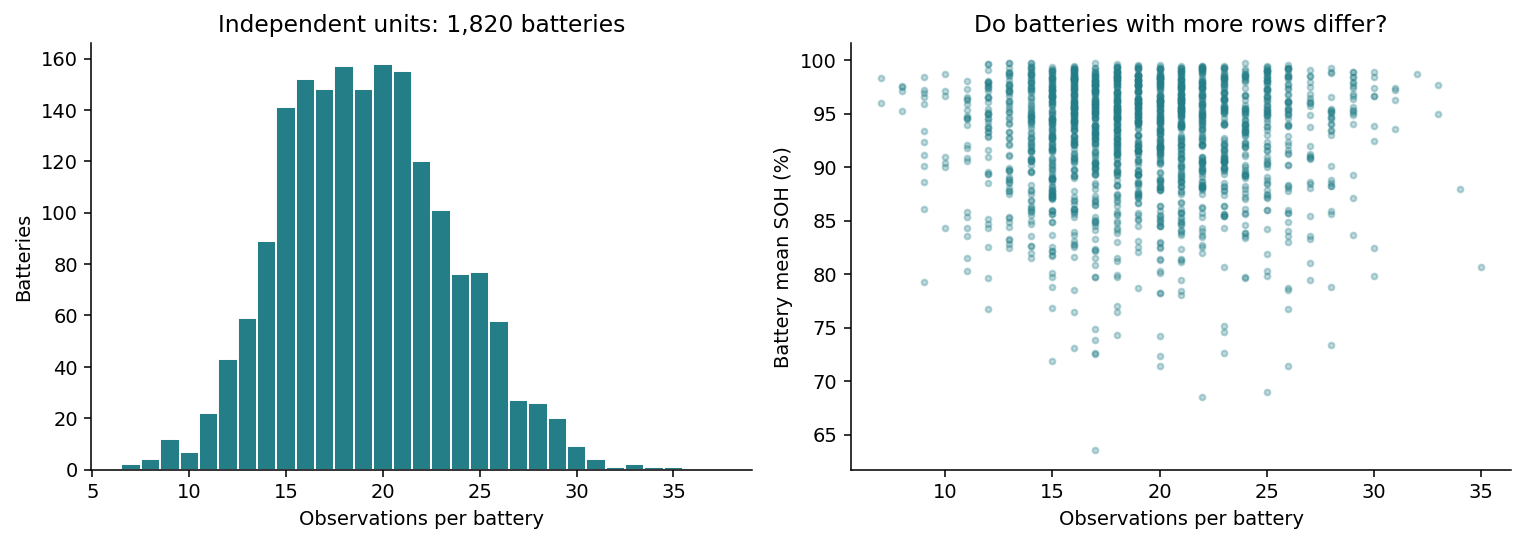

In [4]:
row_weight = 1 / train.groupby("battery_id")[TARGET].transform("size")
per_battery_weights = row_weight.groupby(train.battery_id).sum()
assert np.allclose(per_battery_weights, 1)
display(
    pd.Series(
        {
            "mean_per_observasi": target.mean(),
            "mean_bobot_sama_per_baterai": np.average(target, weights=row_weight),
            "median_per_observasi": target.median(),
            "median_bobot_sama_per_baterai": weighted_quantile(target, row_weight, 0.5),
            "spearman_jumlah_observasi_vs_mean_soh_baterai": t["battery_profiles"].observations.corr(
                t["battery_profiles"].mean_soh, method="spearman"
            ),
        }
    ).to_frame("nilai")
)
show("16_battery_observation_structure.png")

**Interpretasi:** kedua versi hampir sama, sehingga jumlah observasi per baterai tidak terlalu membiaskan ringkasan target. Meski begitu, observasi dalam satu baterai tetap saling berkaitan, sehingga evaluasi per baterai tetap perlu.

## 4. Distribusi fitur numerik

Histogram mencakup 15 fitur numerik, `recall_flag`, dan 4 kolom sensor proxy. Nilai ekstrem tidak dipotong, dan setiap panel mencantumkan jumlah data terisi serta persentase missing value.

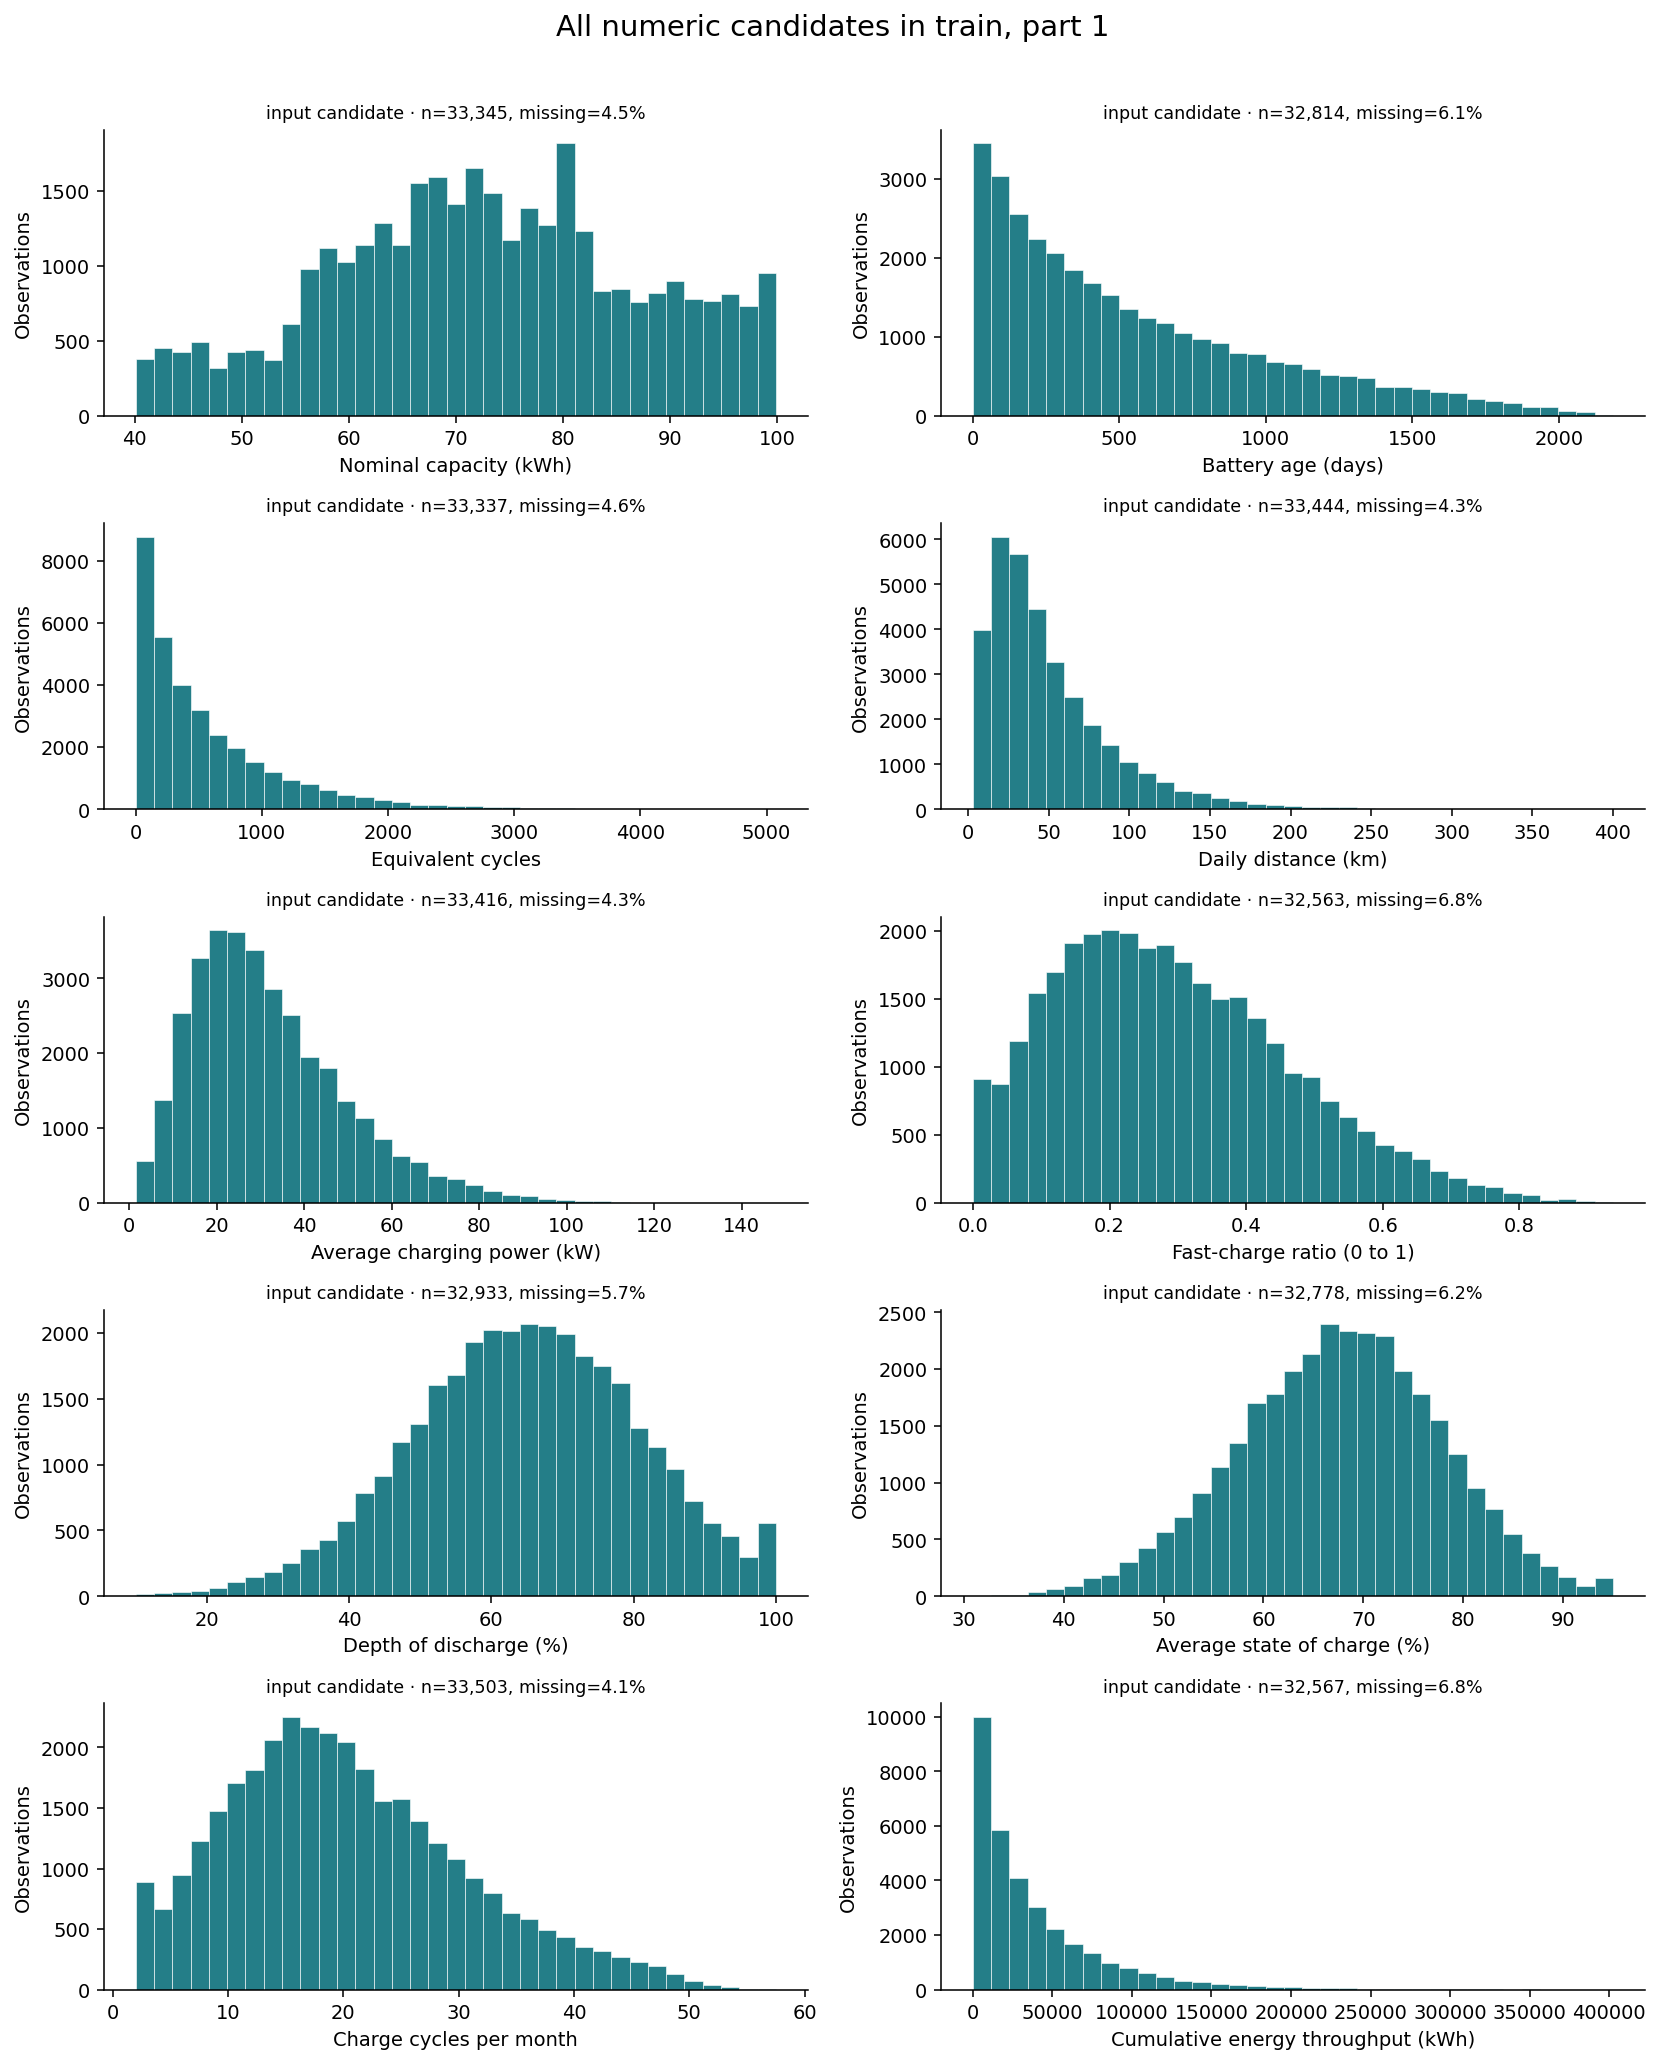

,feature,count,min,1%,25%,50%,75%,99%,max
0,pack_capacity_kwh,33345.0,40.100,41.700,62.500,72.500,82.500,99.400,99.900
1,battery_age_days,32814.0,1.000,6.000,167.000,418.000,835.000,1888.870,2184.000
2,cycle_count,33337.0,1.000,4.000,136.000,372.000,800.000,2802.640,5073.000
3,avg_daily_distance_km,33444.0,3.000,4.700,22.500,39.300,66.800,192.657,400.000
4,avg_charging_power_kw,33416.0,1.496,4.200,19.000,28.600,41.800,85.385,147.772
5,fast_charge_ratio,32563.0,0.000,0.000,0.161,0.272,0.405,0.746,0.937
6,avg_depth_of_discharge_pct,32933.0,10.000,26.300,54.100,65.000,75.900,100.000,100.000
7,avg_state_of_charge_pct,32778.0,30.900,43.300,60.800,67.900,74.600,90.300,95.000
8,charge_cycles_per_month,33503.0,2.000,2.000,12.800,19.000,26.600,47.300,57.500
9,total_energy_throughput_kwh,32567.0,36.400,292.750,8772.200,24155.300,53217.100,200447.024,402419.900


In [5]:
show("02_numeric_distributions_1.png", 1100)
display(
    t["numeric_distributions"][["feature", "count", "min", "1%", "25%", "50%", "75%", "99%", "max"]].round(3)
)

**Interpretasi:** skala antarfitur sangat berbeda. Siklus dan energi kumulatif memiliki ekor kanan yang panjang, sehingga median lebih mewakili nilai tipikal dibanding maksimum.

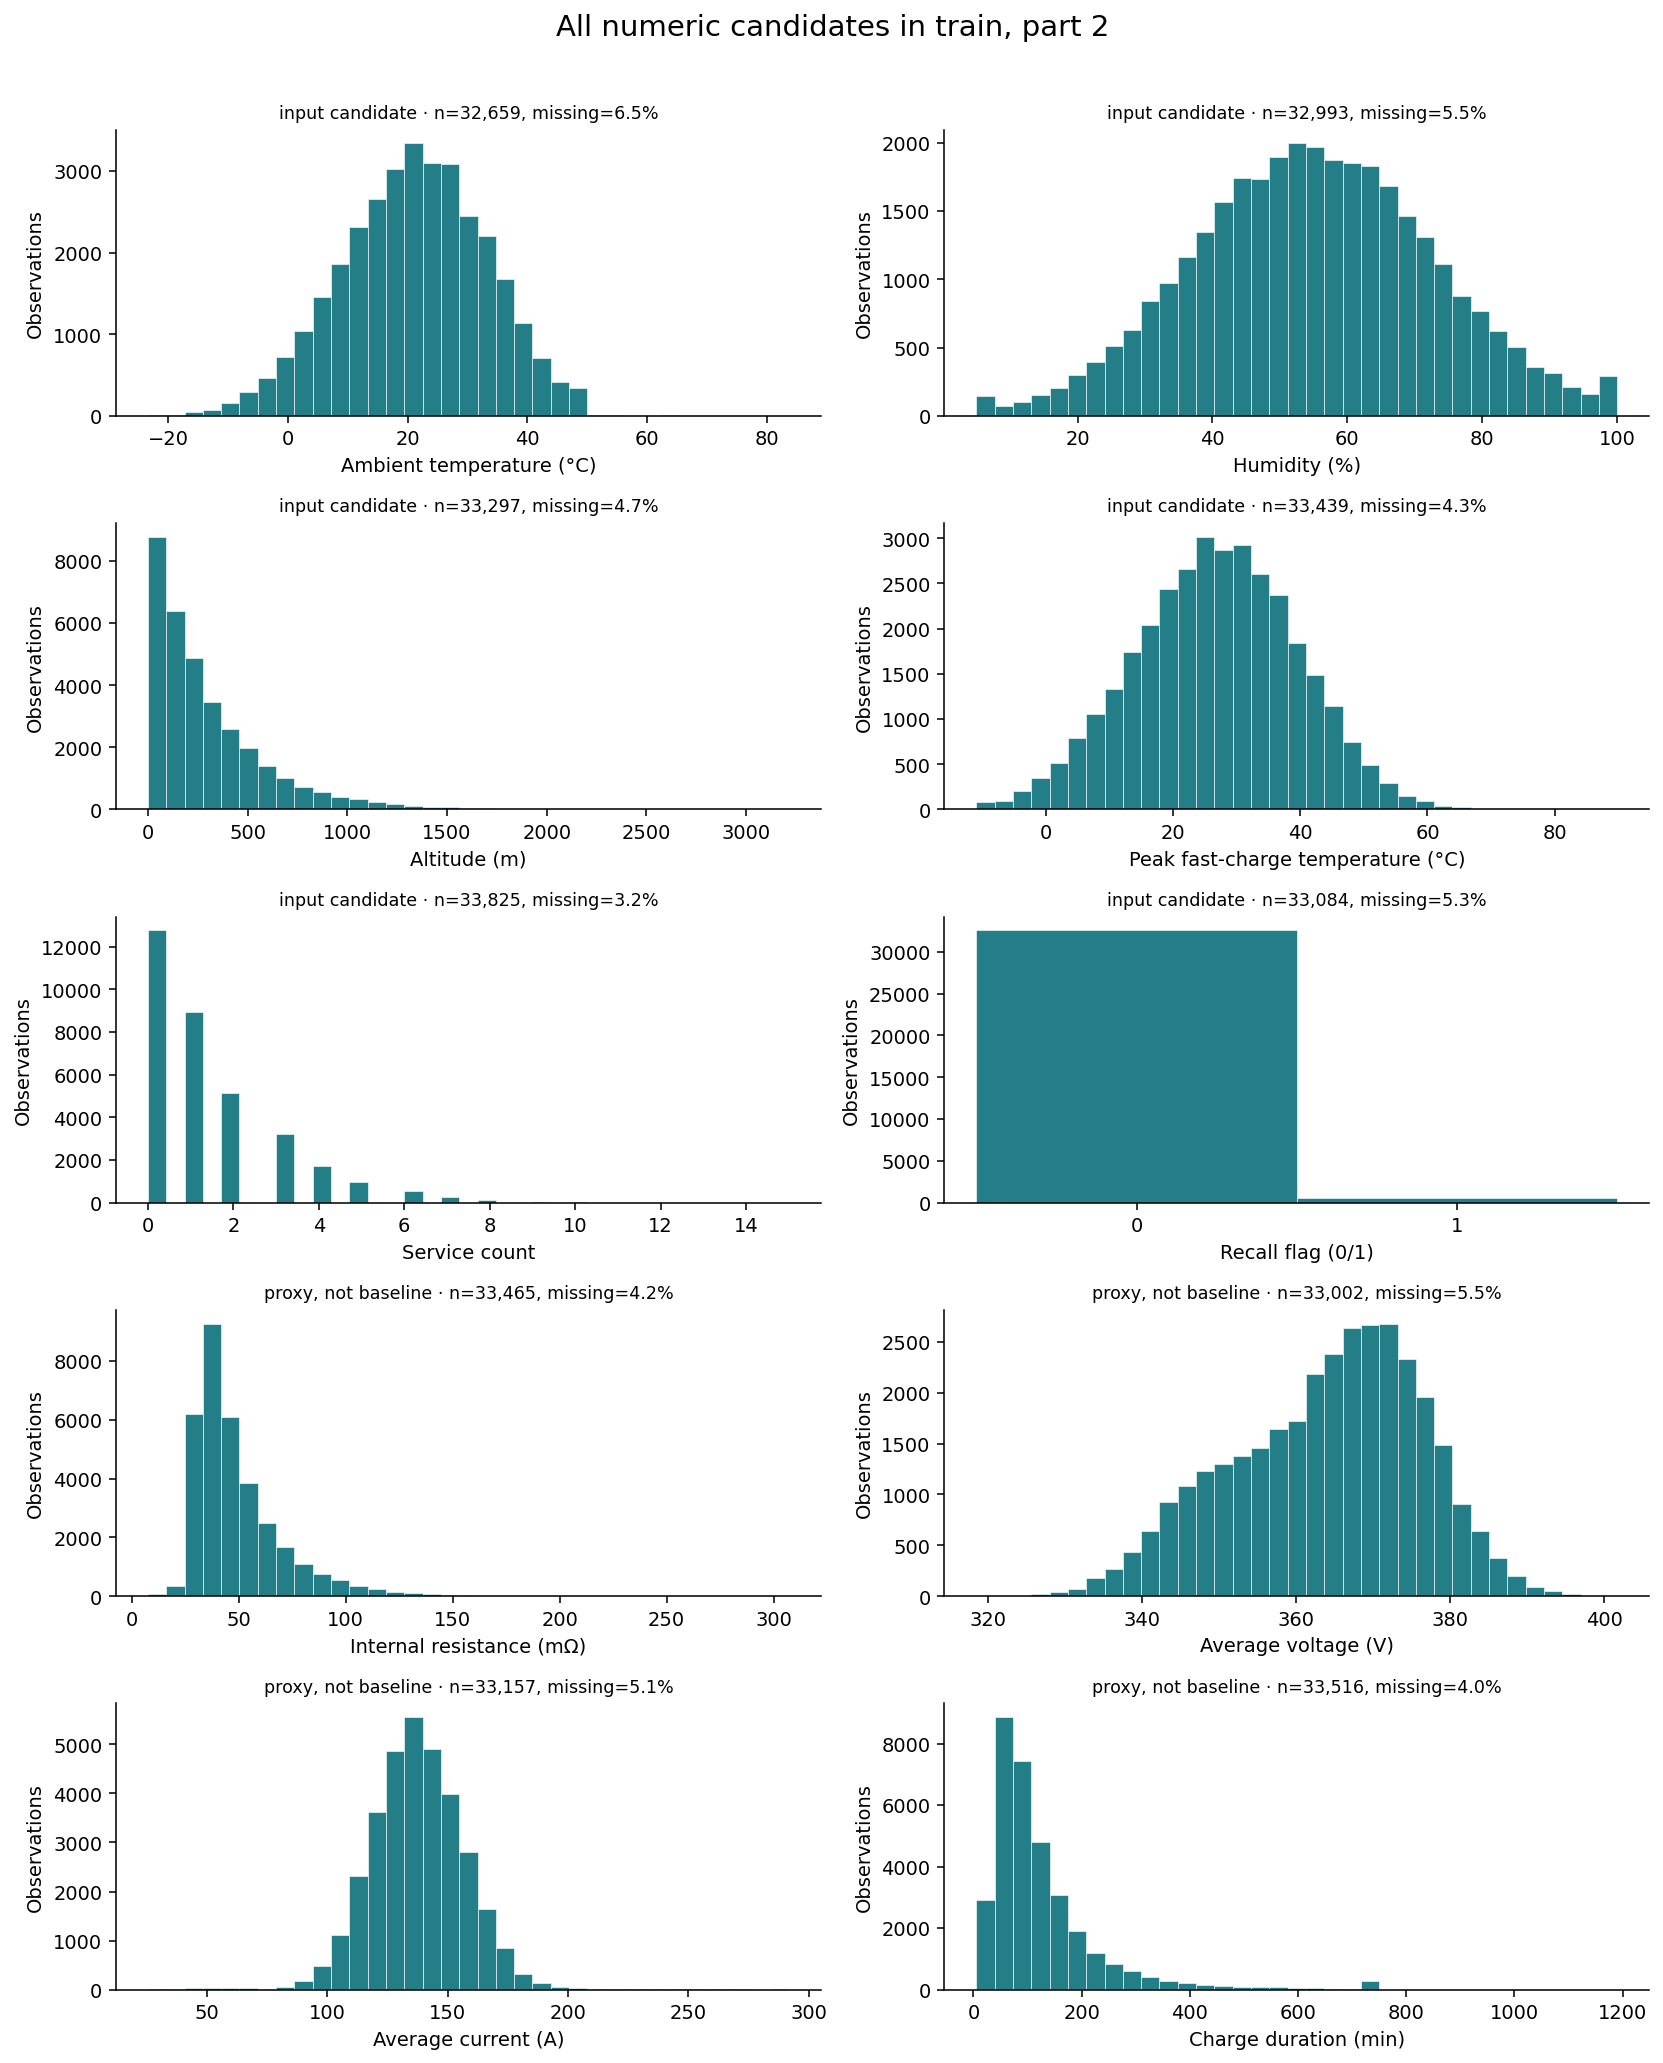

,feature,skewness,median,p99,max
15,recall_flag,7.795,0.000,1.000,1.000
19,charge_time_avg_min,2.807,94.400,650.170,1190.084
9,total_energy_throughput_kwh,2.178,24155.300,200447.024,402419.900
16,internal_resistance_mohm,2.046,42.920,128.471,307.090
12,altitude_m,1.955,209.000,1357.040,3214.000
2,cycle_count,1.918,372.000,2802.640,5073.000
3,avg_daily_distance_km,1.825,39.300,192.657,400.000
14,service_count,1.619,1.000,7.000,15.000
4,avg_charging_power_kw,0.997,28.600,85.385,147.772
1,battery_age_days,0.992,418.000,1888.870,2184.000


In [6]:
show("02_numeric_distributions_2.png", 1100)
display(
    t["tails_and_iqr"][["feature", "skewness", "median", "p99", "max"]]
    .sort_values("skewness", ascending=False)
    .round(3)
)

**Interpretasi:** durasi pengisian dan resistance memiliki ekor panjang. `recall_flag` hampir selalu bernilai 0, sehingga skewness tinggi di sini bukan tanda data salah.

**Implikasi:** normalisasi diperlukan sebelum training. Distribusi yang miring tidak otomatis dihapus, tetapi transformasi log dan capping layak diuji sebagai alternatif.

## 5. Komposisi kategori

Frekuensi tiap kategori diperiksa sebelum membandingkan SOH. Kategori Missing ditampilkan sebagai kelompok tersendiri.

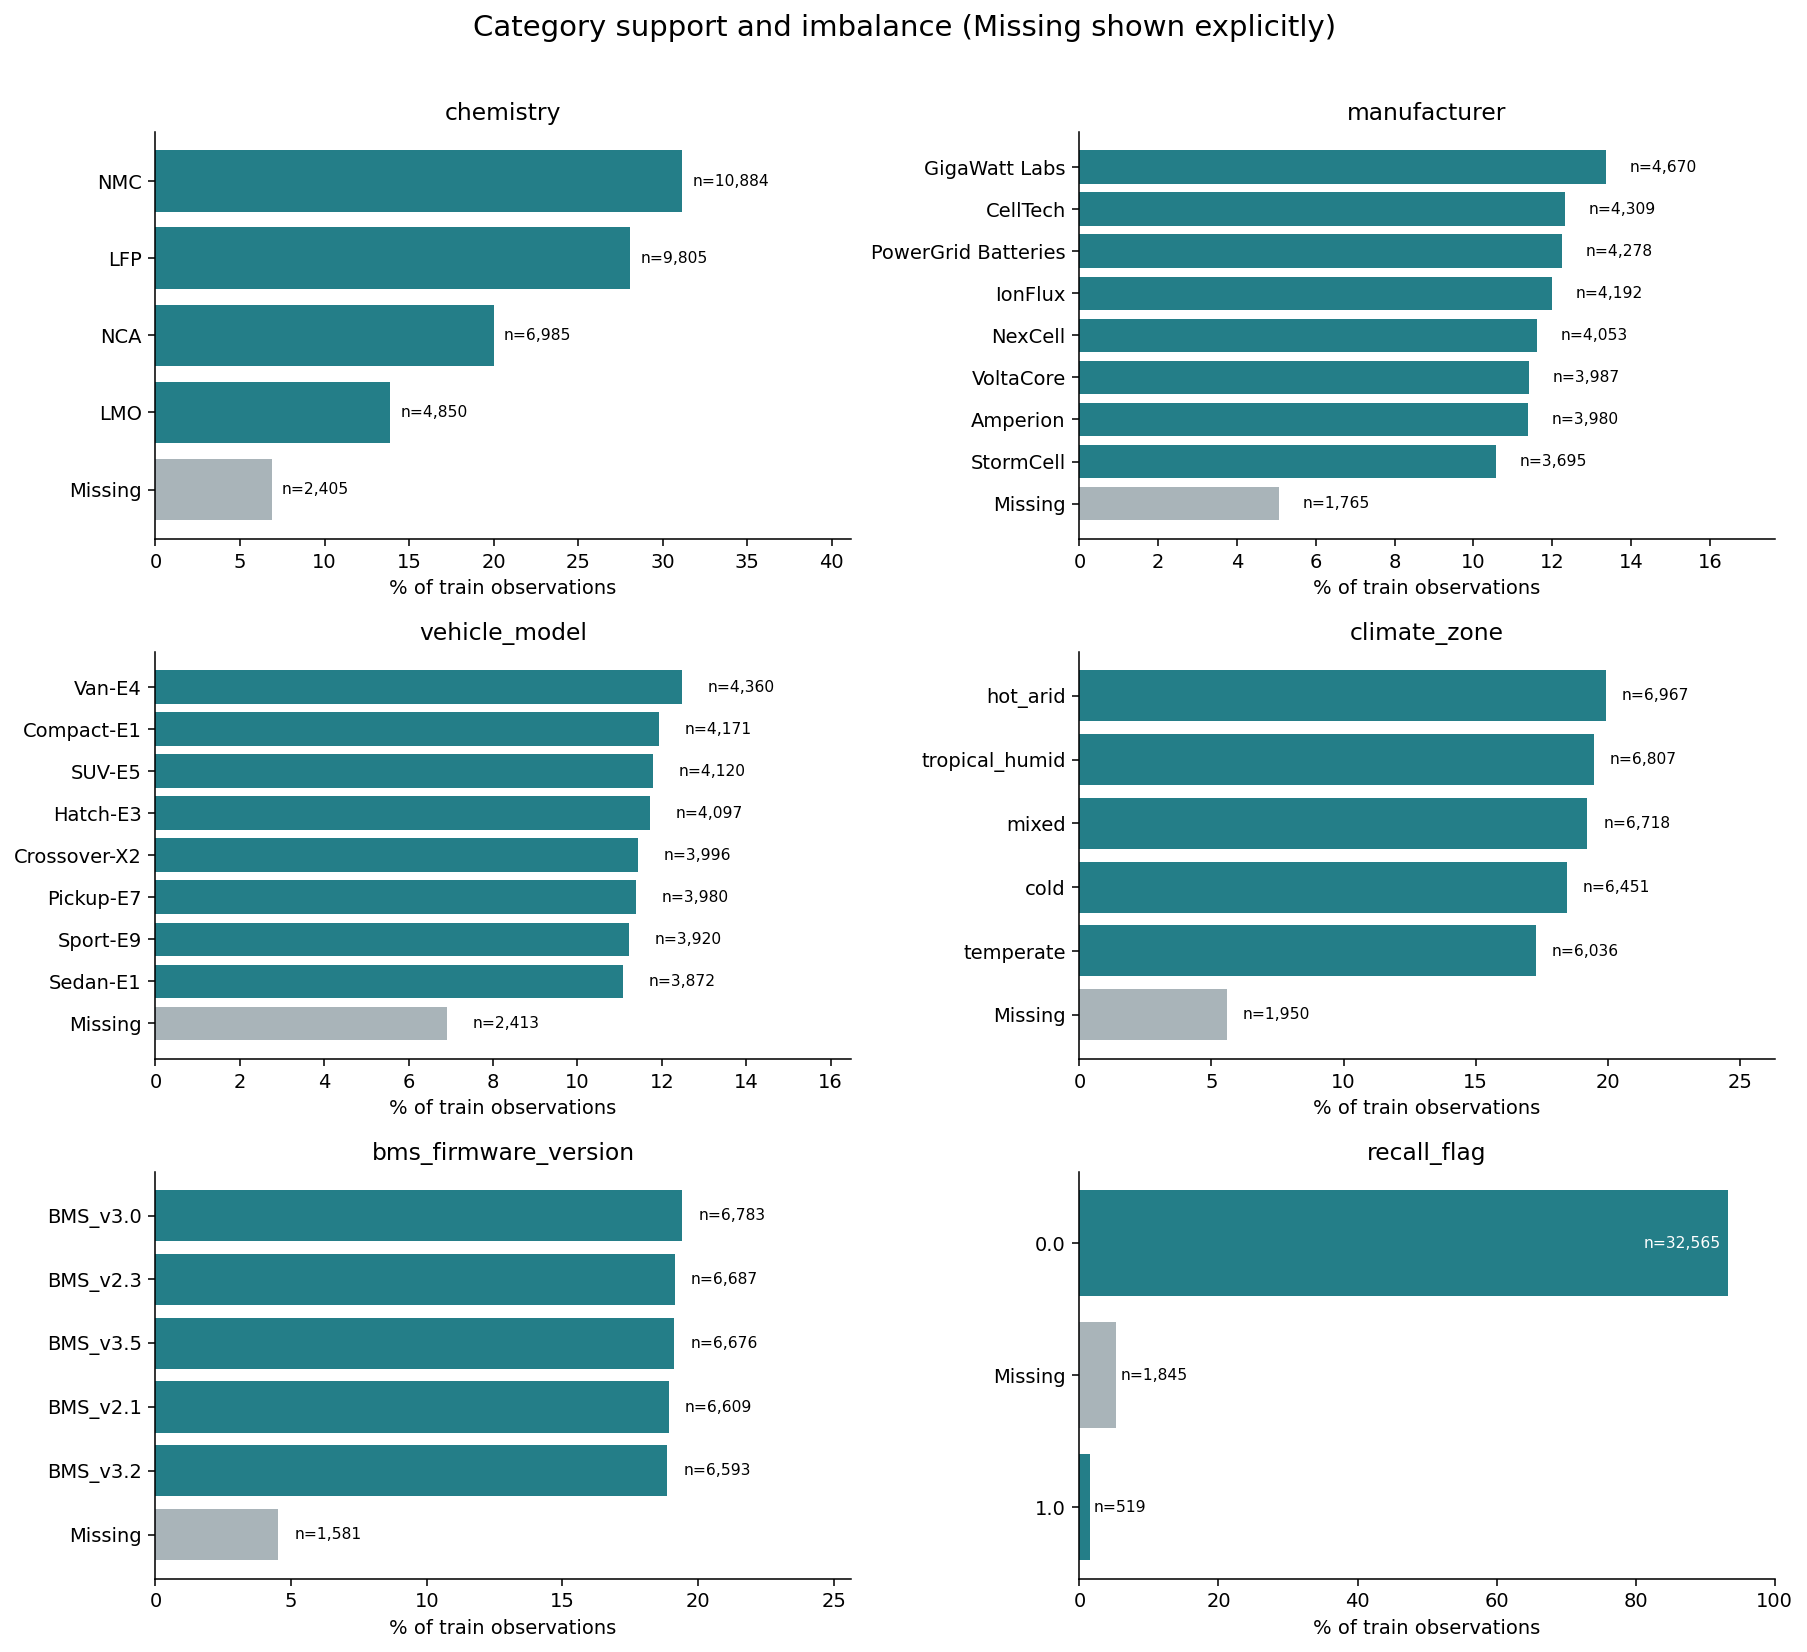

,feature,category,rows,batteries,row_pct
0,chemistry,LFP,9805,546,28.071
1,chemistry,LMO,4850,268,13.885
2,chemistry,Missing,2405,1345,6.885
3,chemistry,NCA,6985,393,19.998
4,chemistry,NMC,10884,613,31.160
5,manufacturer,Amperion,3980,216,11.395
6,manufacturer,CellTech,4309,235,12.336
7,manufacturer,GigaWatt Labs,4670,260,13.370
8,manufacturer,IonFlux,4192,228,12.001
9,manufacturer,Missing,1765,1145,5.053


In [7]:
show("03_categorical_support.png", 1100)
categorical = t["categorical_profiles"]
display(
    categorical.loc[
        categorical.feature.isin(contract["categorical_features"] + ["recall_flag"]),
        ["feature", "category", "rows", "batteries", "row_pct"],
    ].round(3)
)

**Temuan:** ukuran kelompok sangat bervariasi. `recall_flag = 1` hanya sekitar 1,49% observasi train (93,23% bernilai 0 dan 5,28% missing). Kesimpulan dari kelompok sekecil ini harus hati-hati. Encoding untuk kategori baru dan missing ditangani di notebook 02.

## 6. Kimia baterai dan umur

Perbandingan kimia secara langsung bisa bias karena distribusi umur tiap kimia berbeda. Karena itu ada dua ringkasan:

1. Median dan IQR SOH per kimia (per observasi).
2. Rerata SOH per baterai dalam rentang umur tahunan yang sama, dengan bobot sama per baterai.

`chemistry_group` adalah label bantu khusus EDA dan tidak menimpa kolom `chemistry` asli.

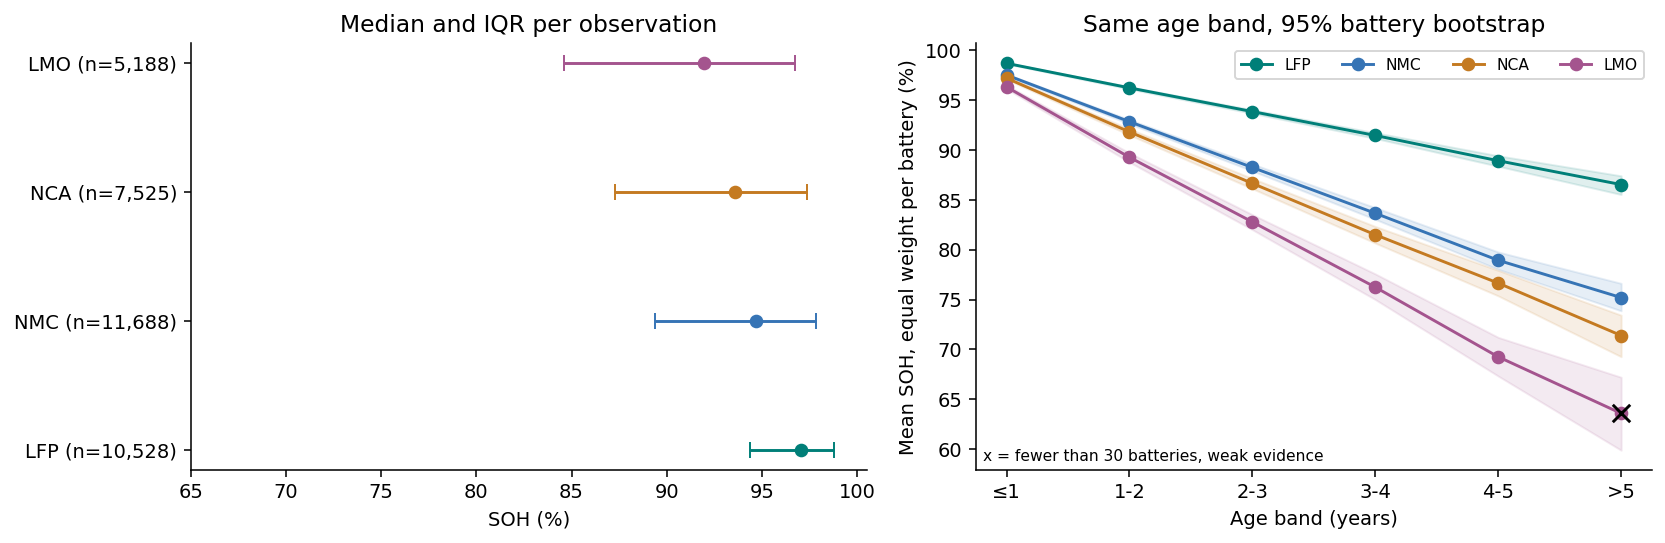

,chemistry,rows,batteries,battery_balanced_mean_soh,ci95_low,ci95_high
1,LFP,2439,469,96.237,96.119,96.348
7,LMO,1168,226,89.270,88.781,89.709
13,NCA,1665,344,91.817,91.513,92.115
19,NMC,2718,501,92.845,92.634,93.038


In [8]:
show("04_chemistry_and_age.png", 1150)
curves = t["chemistry_age_profiles"]
display(
    curves.loc[
        curves.age_band.eq(AGE_LABELS[1]),
        ["chemistry", "rows", "batteries", "battery_balanced_mean_soh", "ci95_low", "ci95_high"],
    ].round(3)
)

**Temuan:** pada umur 1 sampai 2 tahun, rerata SOH per baterai sekitar 96,24% (LFP), 92,84% (NMC), 91,82% (NCA), dan 89,27% (LMO). Perbedaan antarkimia tetap terlihat walaupun umurnya disamakan.

Pita pada grafik adalah interval bootstrap 95% dari 1.000 resampling **baterai** (bukan baris) di setiap sel kimia dan umur. Faktor lain seperti pola pemakaian belum dikontrol, jadi ini bukan bukti sebab akibat.

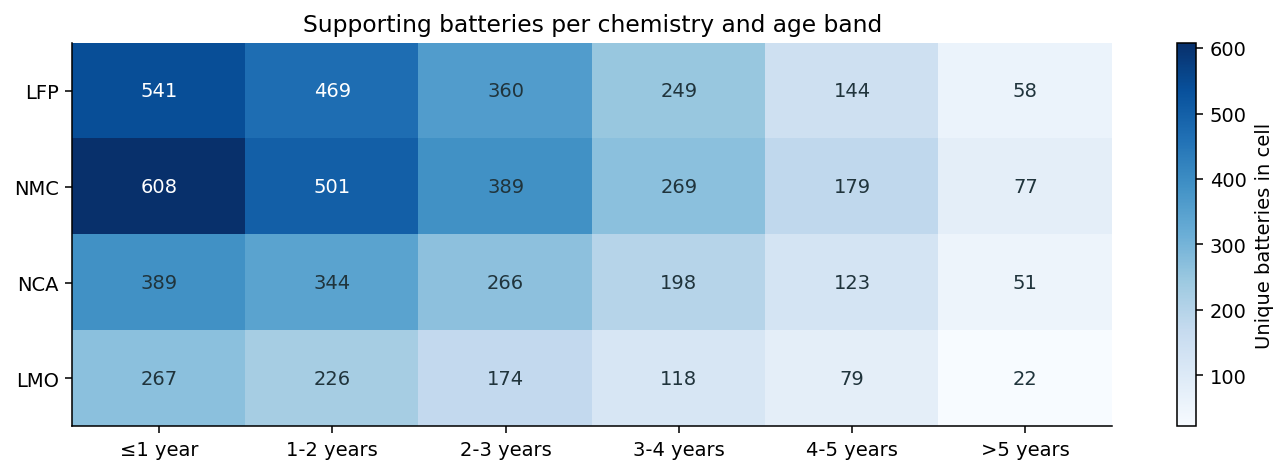

,chemistry,age_band,rows,batteries
11,LMO,>5 years,51,22


In [9]:
show("05_chemistry_age_support.png")
display(curves.loc[~curves.support_at_least_30_batteries, ["chemistry", "age_band", "rows", "batteries"]])
assert curves.battery_balanced_mean_soh.between(curves.ci95_low, curves.ci95_high).all()

**Batas dukungan:** sel LMO berumur lebih dari 5 tahun hanya berisi 22 baterai dan ditandai x pada kurva. Semakin sedikit baterai, semakin lemah kesimpulannya.

## 7. Korelasi fitur numerik

- **Pearson** mengukur hubungan linear.
- **Spearman** mengukur hubungan monoton berbasis ranking.

Setiap pasangan memakai baris yang lengkap untuk pasangan itu saja, tanpa imputasi. Jumlah pasangan yang dipakai ikut ditampilkan.

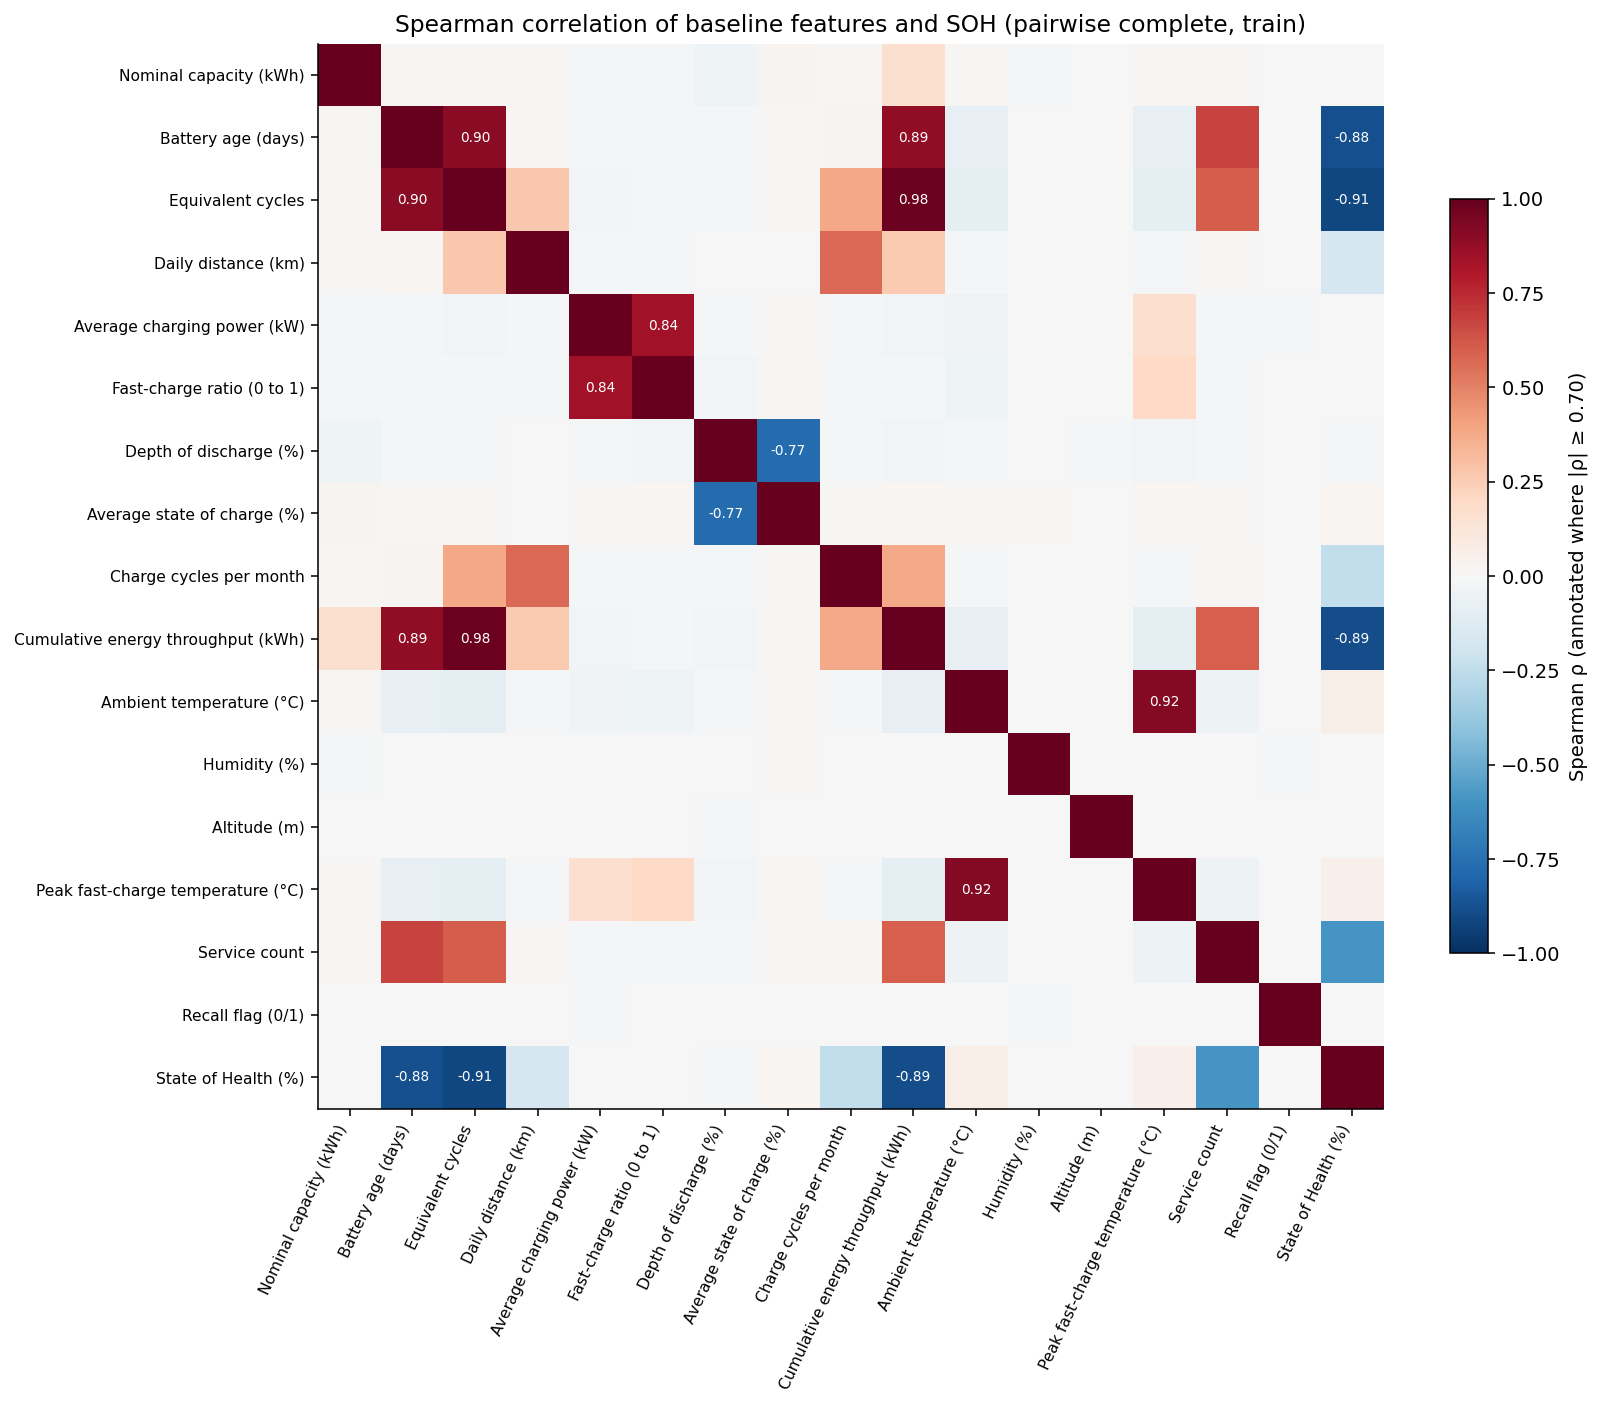

,feature,pairwise_rows,batteries,pearson_pooled,spearman_pooled,pearson_between_battery_means,pearson_within_battery_centered,role
2,cycle_count,33337,1820,-0.873,-0.907,-0.829,-0.922,primary
16,internal_resistance_mohm,33465,1820,-0.928,-0.896,-0.916,-0.942,proxy_not_baseline
9,total_energy_throughput_kwh,32567,1820,-0.822,-0.886,-0.767,-0.892,primary
1,battery_age_days,32814,1820,-0.809,-0.881,-0.731,-0.898,primary
14,service_count,33825,1820,-0.564,-0.593,-0.685,-0.542,primary
8,charge_cycles_per_month,33503,1820,-0.275,-0.244,-0.406,0.010,primary
3,avg_daily_distance_km,33444,1820,-0.177,-0.169,-0.377,-0.004,primary
10,avg_ambient_temp_c,32659,1820,0.024,0.056,0.006,0.052,primary
13,peak_temp_during_fast_charge_c,33439,1820,0.022,0.053,0.004,0.042,primary
17,voltage_avg_v,33002,1820,0.048,0.023,0.078,0.008,proxy_not_baseline


,pack_capacity_kwh,battery_age_days,cycle_count,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,avg_depth_of_discharge_pct,...,service_count,recall_flag,internal_resistance_mohm,voltage_avg_v,current_avg_a,charge_time_avg_min,state_of_health_pct
pack_capacity_kwh,33345,31324,31824,31929,31907,31076,31438,...,32289,31596,31949,31502,31656,31988,33345
battery_age_days,31324,32814,31304,31393,31386,30602,30941,...,31767,31061,31441,31033,31140,31476,32814
cycle_count,31824,31304,33337,31935,31885,31065,31416,...,32290,31579,31944,31511,31639,31992,33337
avg_daily_distance_km,31929,31393,31935,33444,31978,31161,31528,...,32377,31689,32054,31607,31751,32092,33444
avg_charging_power_kw,31907,31386,31885,31978,33416,31147,31498,...,32363,31650,32022,31576,31735,32070,33416
fast_charge_ratio,31076,30602,31065,31161,31147,32563,30704,...,31527,30847,31186,30775,30920,31239,32563
avg_depth_of_discharge_pct,31438,30941,31416,31528,31498,30704,32933,...,31896,31195,31547,31144,31279,31616,32933
avg_state_of_charge_pct,31298,30803,31285,31378,31355,30553,30917,...,31738,31046,31409,30965,31102,31445,32778
charge_cycles_per_month,31991,31468,31977,32081,32058,31234,31584,...,32451,31724,32111,31647,31801,32145,33503
total_energy_throughput_kwh,31092,30582,31064,31174,31164,30368,30704,...,31545,30857,31210,30775,30920,31251,32567


In [10]:
show("06_baseline_correlations.png", 1150)
assoc = t["target_associations"]
display(assoc.sort_values("spearman_pooled", key=abs, ascending=False).round(3))
display(t["correlation_pair_counts"])

**Temuan:** `cycle_count` (Spearman -0,907), energi kumulatif (-0,886), dan umur (-0,881) berhubungan kuat dengan SOH. Resistance juga kuat (-0,896), tetapi kolom ini adalah proxy sensor yang dikeluarkan dari baseline.

Korelasi rendah tidak berarti fitur tidak berguna, karena MLP dapat menangkap hubungan nonlinear dan interaksi.

,feature_a,feature_b,spearman,pairwise_rows
2,cycle_count,total_energy_throughput_kwh,0.984,31064
5,avg_ambient_temp_c,peak_temp_during_fast_charge_c,0.920,31255
0,battery_age_days,cycle_count,0.903,31304
1,battery_age_days,total_energy_throughput_kwh,0.890,30582
3,avg_charging_power_kw,fast_charge_ratio,0.841,31147
4,avg_depth_of_discharge_pct,avg_state_of_charge_pct,-0.767,30917


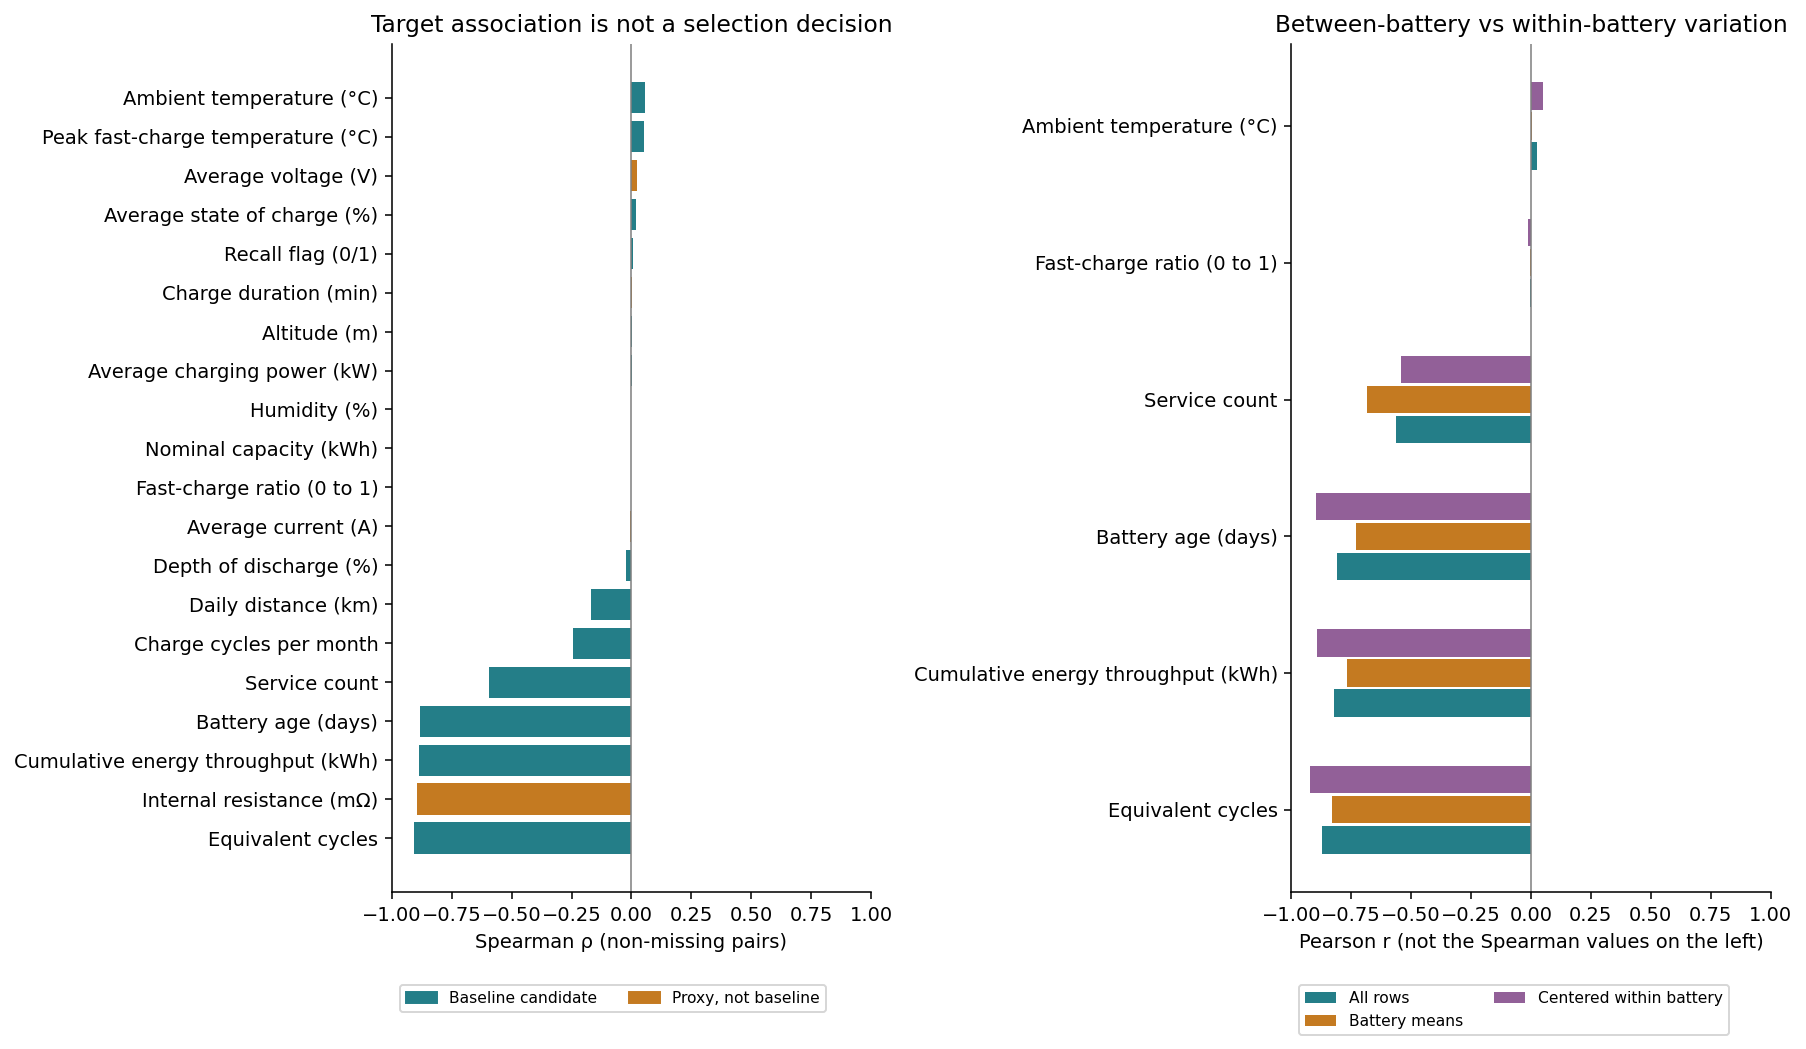

In [11]:
display(t["redundant_pairs"].round(3))
show("07_target_associations_and_dependence.png", 1150)

**Redundansi:** siklus dan energi kumulatif berkorelasi sekitar 0,984, suhu lingkungan dan suhu puncak fast charge sekitar 0,920, serta umur dan siklus sekitar 0,903.

Panel kanan memakai Pearson dan memisahkan tiga sudut pandang: semua baris, rerata per baterai, dan variasi di dalam baterai.

**Implikasi:** fitur yang redundan menjadi kandidat feature selection. Pengaruhnya diuji lewat resep `compact` di notebook 02 dan dibandingkan pada validation.

## 8. Hubungan fitur dan SOH per kimia

Scatter plot memakai sampel tetap 6.000 observasi train. Warna menunjukkan kimia baterai.

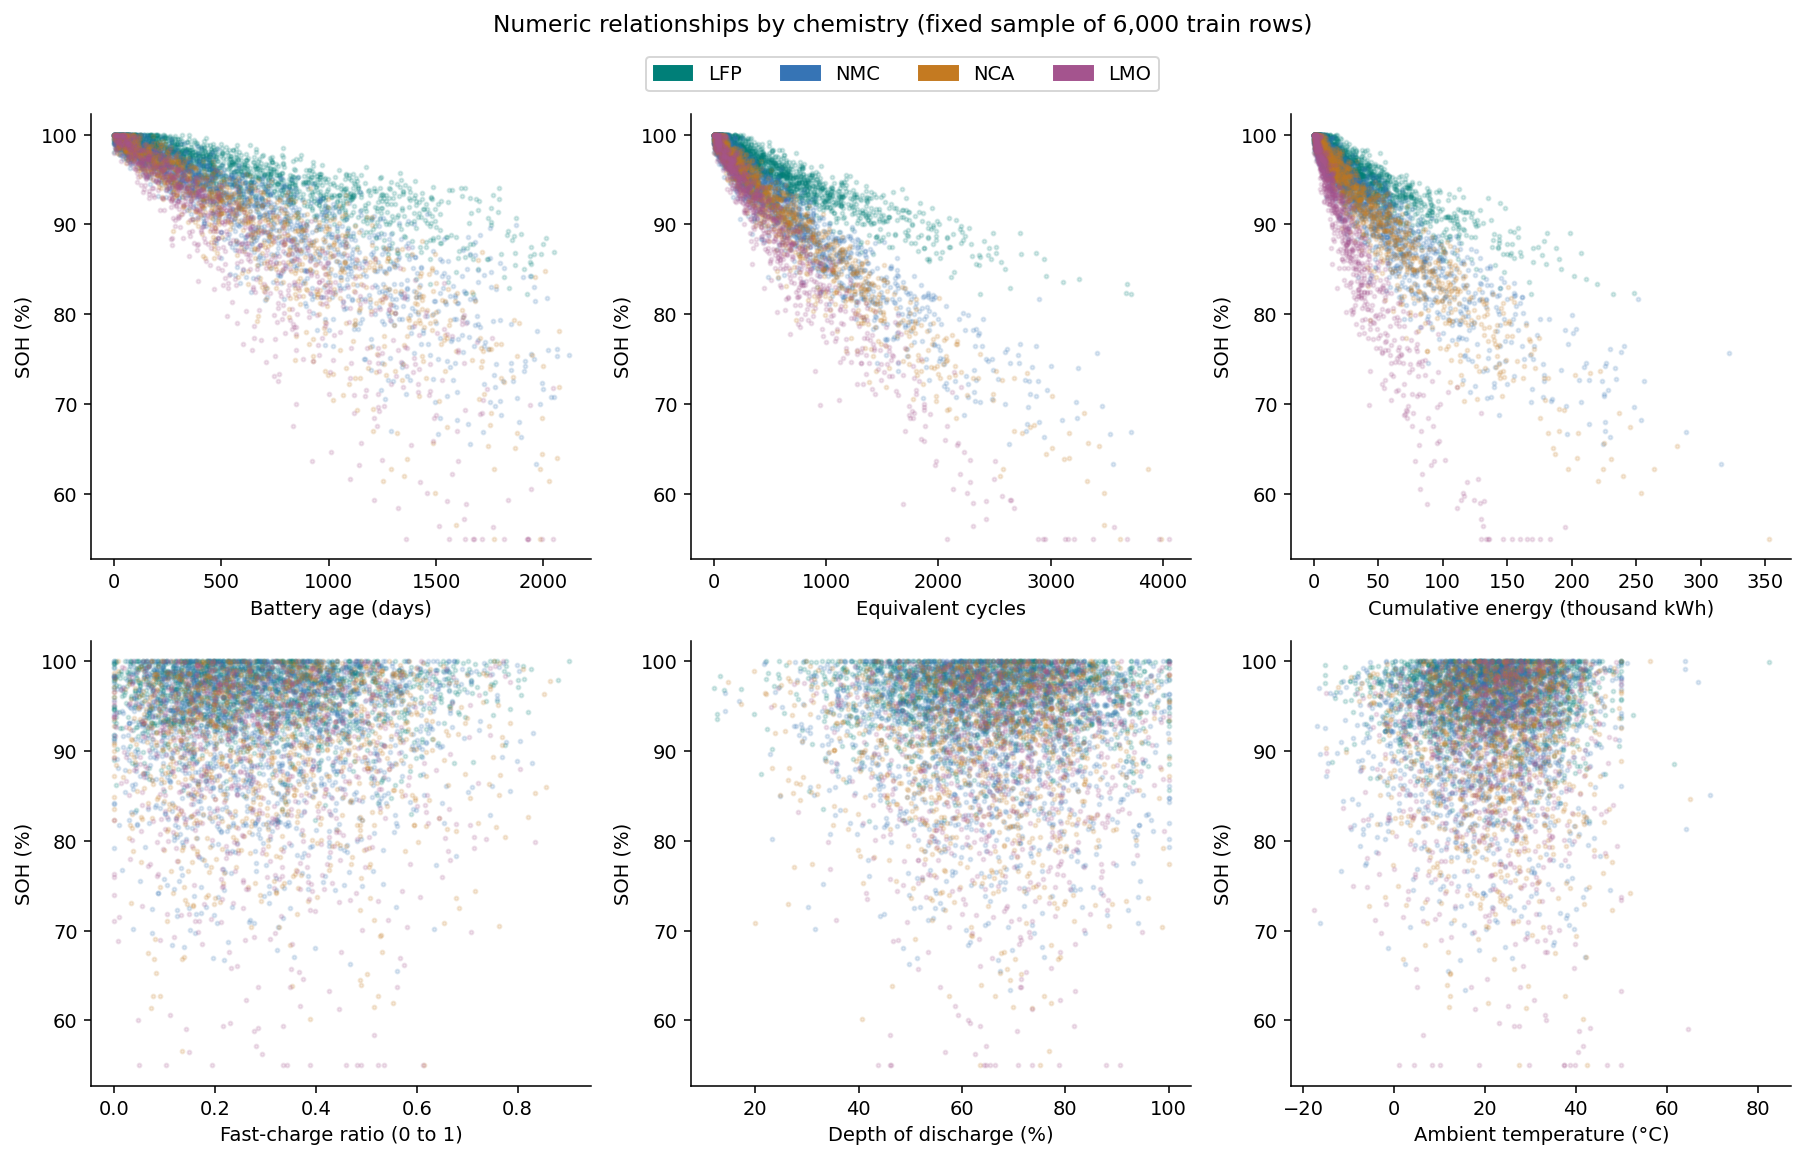

In [12]:
show("08_relationships_by_chemistry.png", 1150)

**Interpretasi:** umur, siklus, dan energi yang tinggi cenderung disertai SOH yang lebih rendah, tetapi sebarannya berbeda antarkimia. Satu koefisien korelasi tidak menggambarkan seluruh pola. Ini alasan untuk mencoba model nonlinear seperti MLP.

## 9. Pola bersyarat: fast charge

Secara keseluruhan, korelasi Spearman fast charge dengan SOH hanya sekitar -0,003. Ini tidak berarti fast charge aman, karena efeknya bisa tertutup oleh perbedaan umur dan kimia. Grid berikut melihat SOH di dalam rentang umur yang sama.

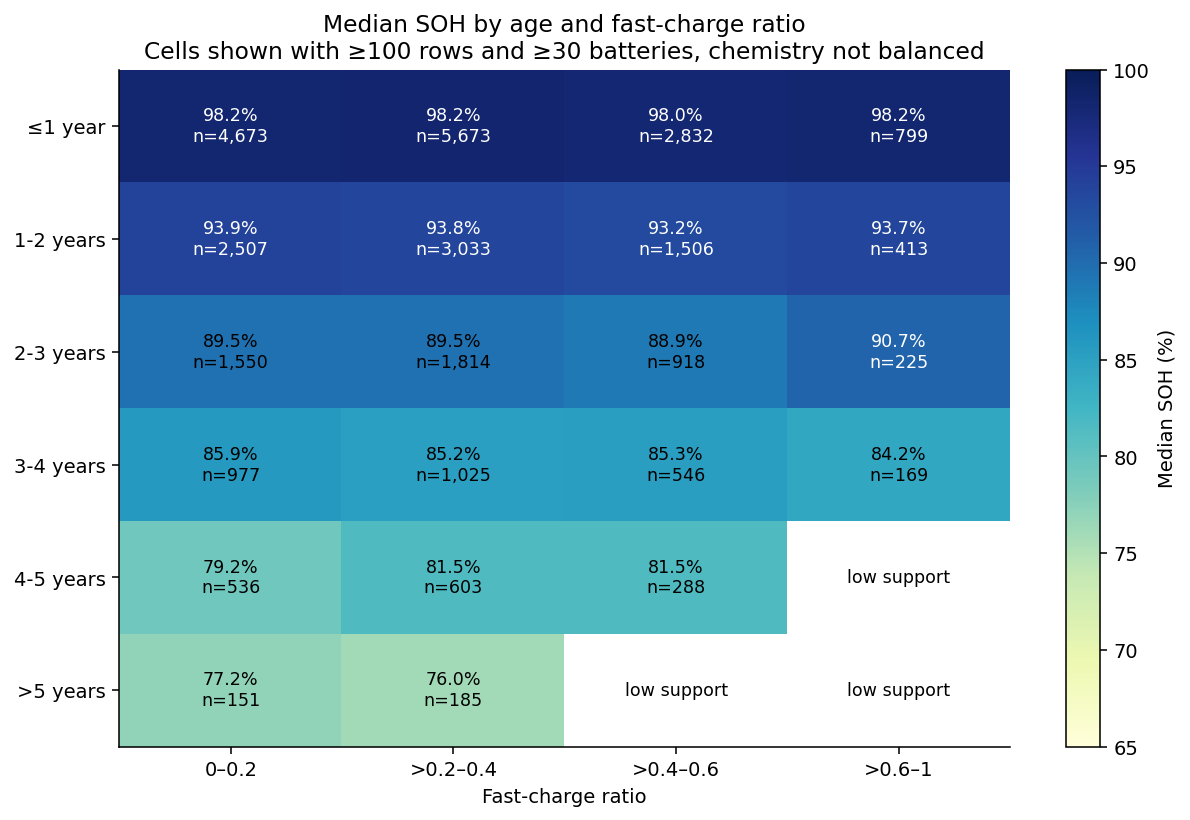

,cells,median_rho,min_rho,max_rho
feature,,,,
avg_ambient_temp_c,23,0.057,-0.216,0.185
avg_depth_of_discharge_pct,23,-0.076,-0.284,-0.007
charge_cycles_per_month,23,-0.770,-0.828,-0.249
fast_charge_ratio,23,-0.026,-0.263,0.159
service_count,23,-0.090,-0.208,0.128


,chemistry,age_band,feature,rows,batteries,spearman
0,LFP,≤1 year,fast_charge_ratio,4173,540,-0.026
5,LFP,1-2 years,fast_charge_ratio,2280,467,-0.042
10,LFP,2-3 years,fast_charge_ratio,1399,358,-0.069
15,LFP,3-4 years,fast_charge_ratio,817,247,0.016
20,LFP,4-5 years,fast_charge_ratio,406,142,-0.165
25,LFP,>5 years,fast_charge_ratio,125,55,-0.173
30,LMO,≤1 year,fast_charge_ratio,2129,266,-0.005
35,LMO,1-2 years,fast_charge_ratio,1093,224,-0.080
40,LMO,2-3 years,fast_charge_ratio,682,172,-0.135
45,LMO,3-4 years,fast_charge_ratio,387,115,-0.093


In [13]:
show("09_age_fastcharge_conditioning.png")
strata = t["stratified_associations"]
display(
    strata.groupby("feature")
    .agg(
        cells=("spearman", "count"),
        median_rho=("spearman", "median"),
        min_rho=("spearman", "min"),
        max_rho=("spearman", "max"),
    )
    .round(3)
)
display(strata.loc[strata.feature.eq("fast_charge_ratio")].round(3))

**Interpretasi:** perubahan median SOH terutama mengikuti umur (antarbaris grid), sedangkan variasi fast charge di dalam satu rentang umur lebih kecil. Sel dengan kurang dari 100 baris atau 30 baterai tidak ditampilkan.

## 10. Produsen, model, iklim, dan firmware

Median SOH ditampilkan bersama jumlah data dan median umur. Sumbu SOH dimulai dari 90% agar selisih kecil terlihat.

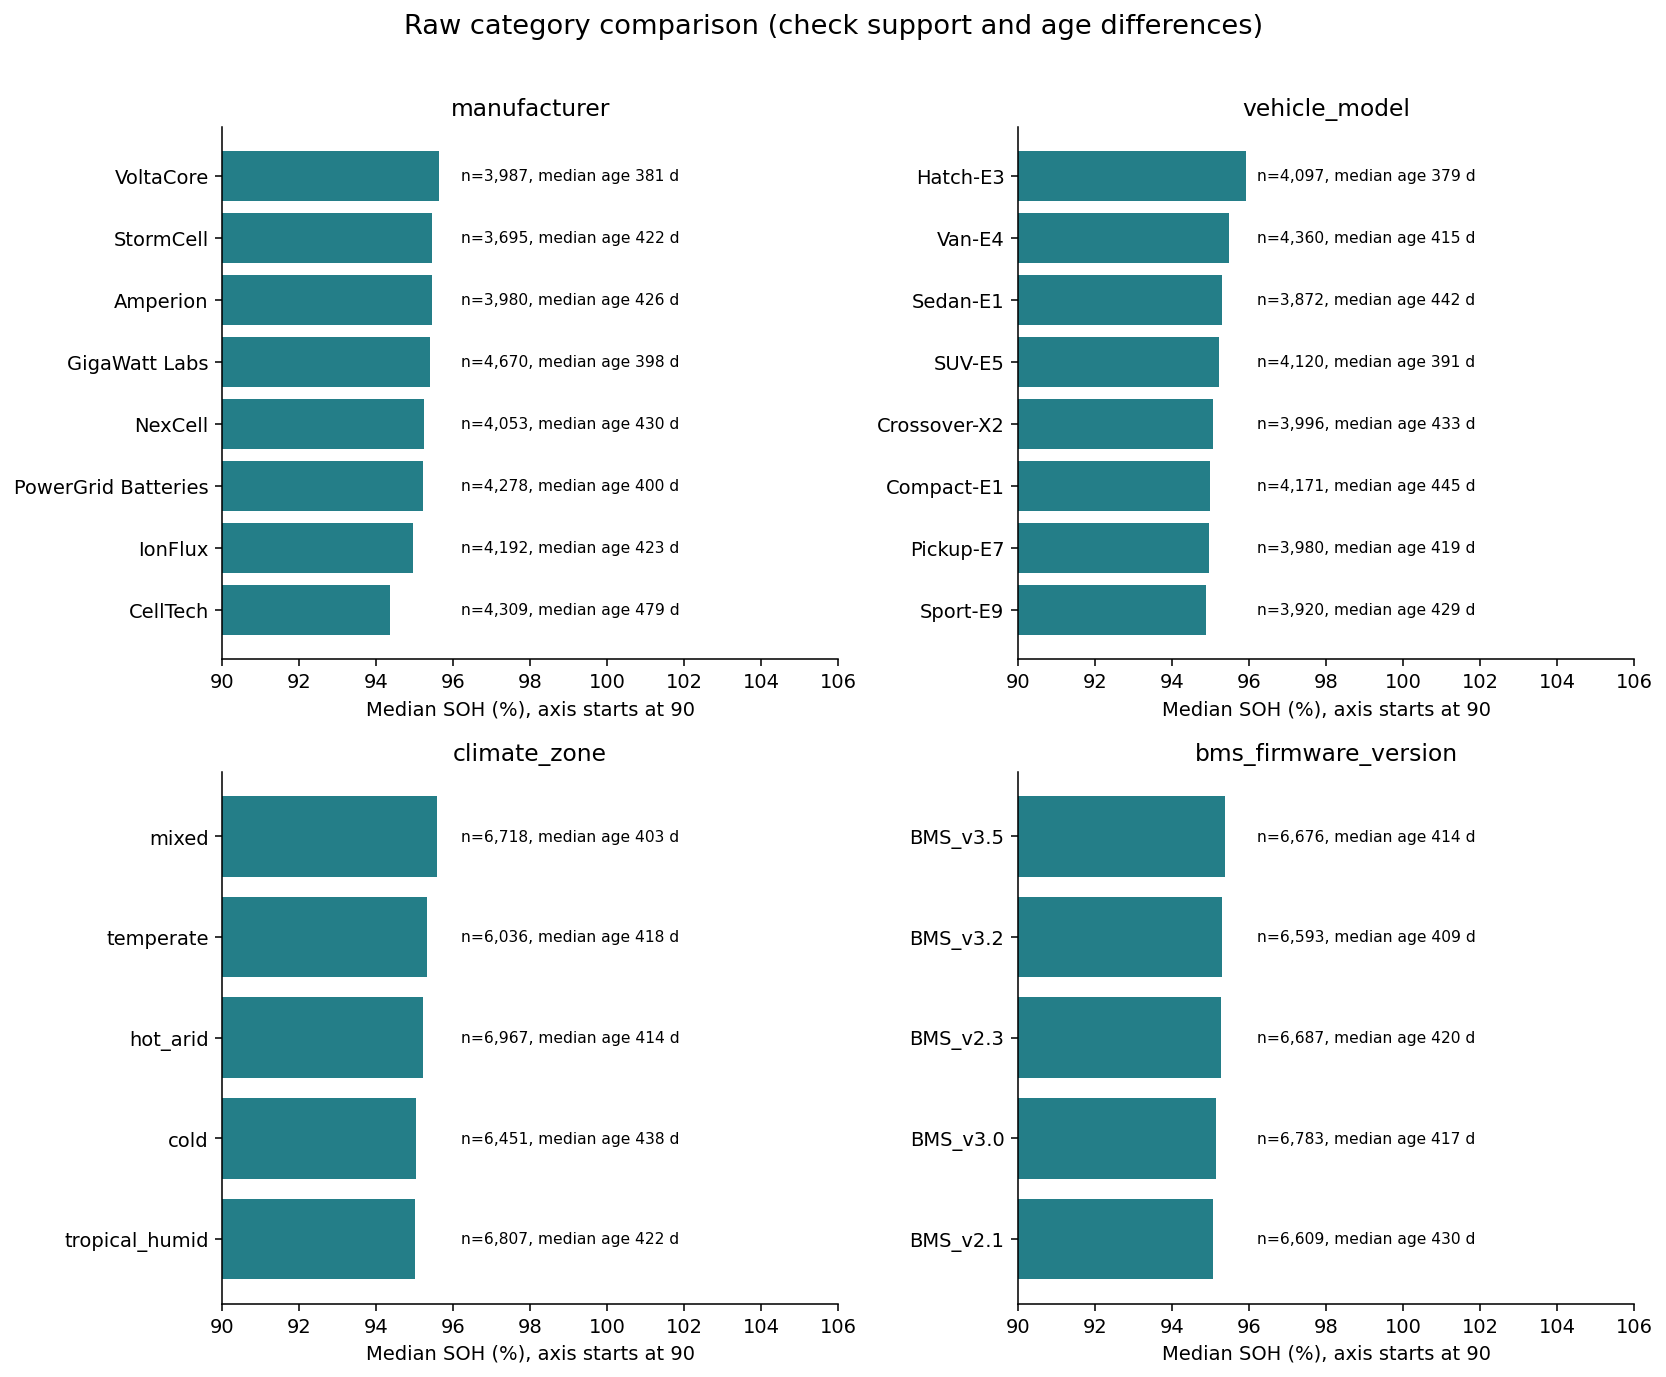

,feature,category,rows,batteries,median_soh,median_age_days,median_cycles
5,manufacturer,Amperion,3980,216,95.440,426.0,360.0
6,manufacturer,CellTech,4309,235,94.370,479.0,456.0
7,manufacturer,GigaWatt Labs,4670,260,95.405,398.0,340.0
8,manufacturer,IonFlux,4192,228,94.965,423.0,372.0
9,manufacturer,Missing,1765,1145,95.340,420.0,373.0
10,manufacturer,NexCell,4053,226,95.240,430.0,362.0
11,manufacturer,PowerGrid Batteries,4278,236,95.215,400.0,368.0
12,manufacturer,StormCell,3695,200,95.450,422.0,364.0
13,manufacturer,VoltaCore,3987,219,95.620,381.0,356.0
14,vehicle_model,Compact-E1,4171,230,94.980,445.0,388.0


In [14]:
show("10_category_comparisons.png", 1100)
display(
    categorical.loc[
        categorical.feature.isin(["manufacturer", "vehicle_model", "climate_zone", "bms_firmware_version"]),
        ["feature", "category", "rows", "batteries", "median_soh", "median_age_days", "median_cycles"],
    ].round(3)
)

**Interpretasi:** median SOH antarkategori relatif berdekatan, dan median umurnya juga berbeda. Contohnya, Hatch-E3 memiliki median umur lebih rendah, sehingga SOH-nya yang lebih tinggi belum tentu karena modelnya lebih baik. Nilai firmware berubah antarobservasi, jadi tidak bisa dianggap atribut tetap baterai.

## 11. Pola missing value

Tiga hal yang diperiksa: jumlah missing per baris, perbedaan SOH antara baris missing dan terisi, dan korelasi antarindikator missing.

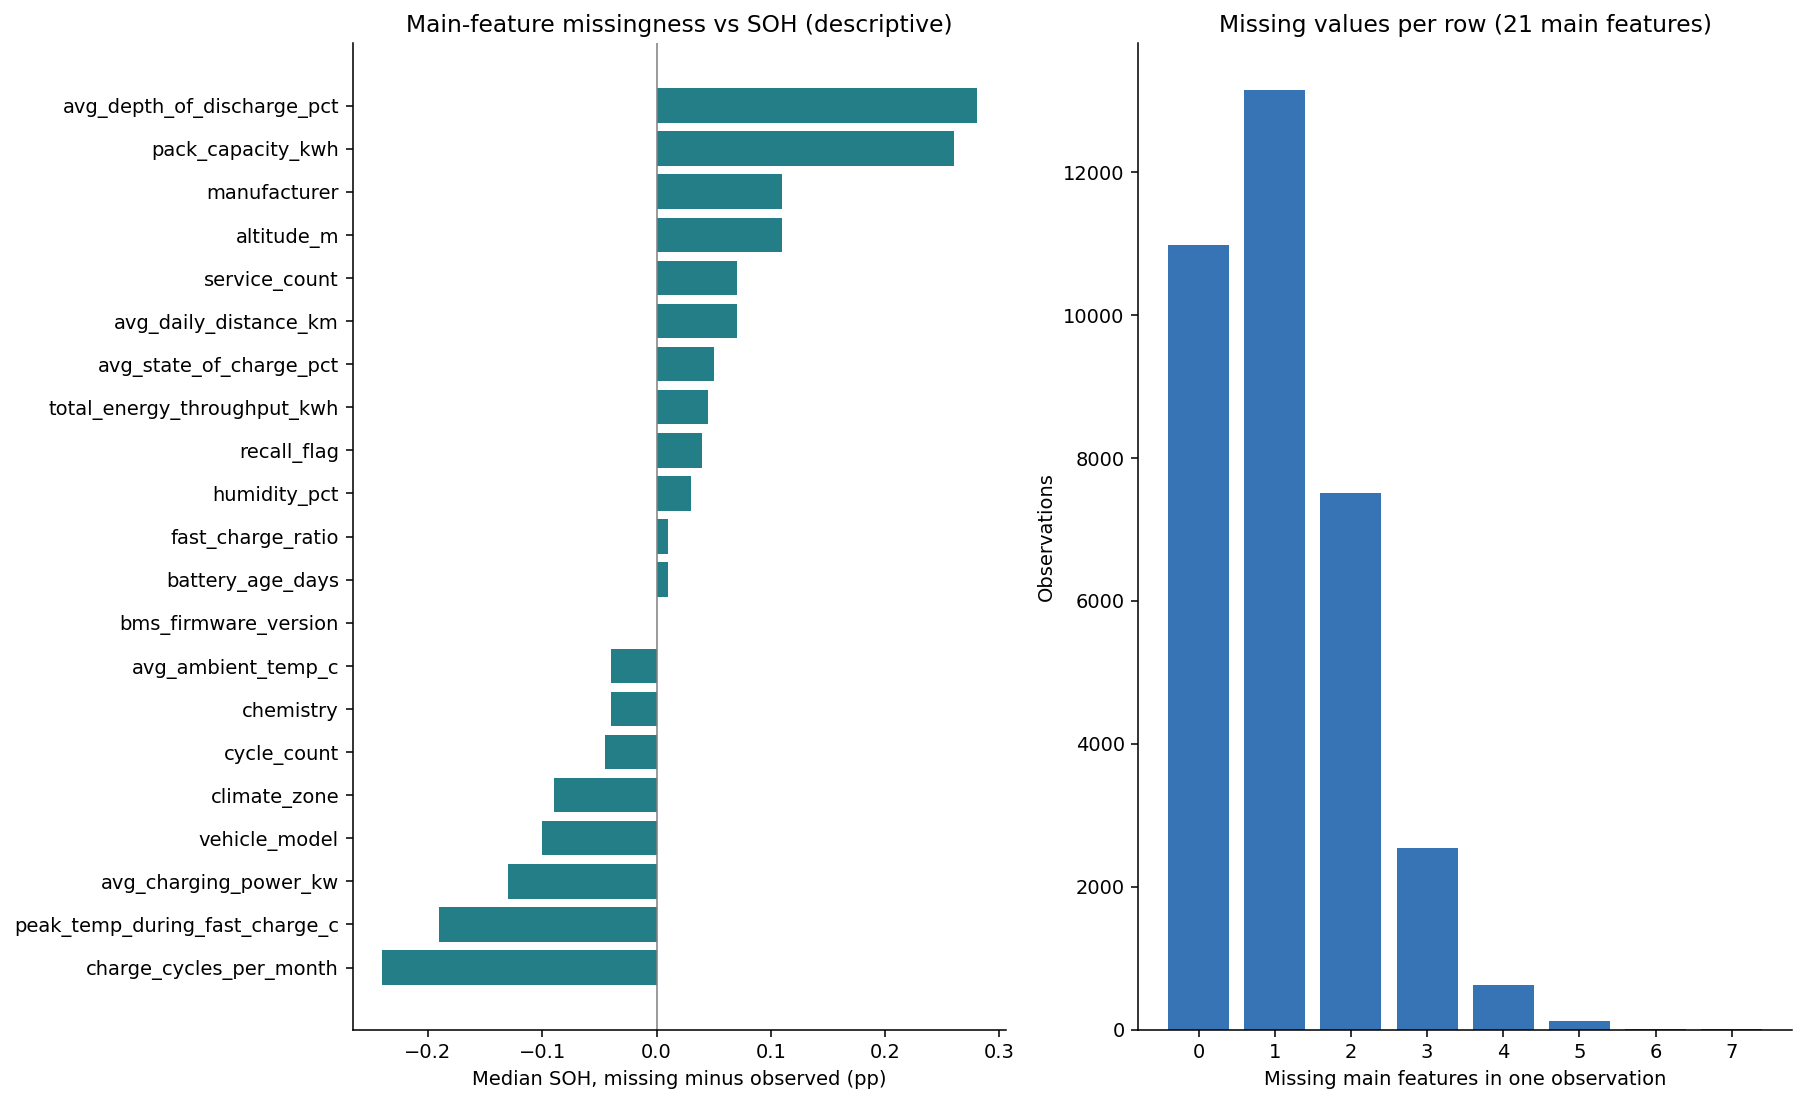

,feature,missing_rows,missing_pct,observed_rows,median_soh_missing,median_soh_observed,median_gap_missing_minus_observed,median_age_missing,median_age_observed
0,chemistry,2405,6.885,32524,95.200,95.24,-0.040,429.5,417.0
1,manufacturer,1765,5.053,33164,95.340,95.23,0.110,420.0,418.0
2,vehicle_model,2413,6.908,32516,95.140,95.24,-0.100,421.0,418.0
3,pack_capacity_kwh,1584,4.535,33345,95.480,95.22,0.260,401.0,419.0
4,manufacture_date,1356,3.882,33573,95.505,95.22,0.285,393.0,419.0
5,observation_date,1581,4.526,33348,95.180,95.24,-0.060,428.0,418.0
6,battery_age_days,2115,6.055,32814,95.240,95.23,0.010,NaN,418.0
7,cycle_count,1592,4.558,33337,95.195,95.24,-0.045,422.0,418.0
8,climate_zone,1950,5.583,32979,95.150,95.24,-0.090,412.0,419.0
9,avg_daily_distance_km,1485,4.251,33444,95.300,95.23,0.070,413.0,419.0


,feature_a,feature_b,phi
283,avg_depth_of_discharge_pct,last_service_date,0.017
202,climate_zone,total_energy_throughput_kwh,0.017
396,capacity_fade_pct,service_count,0.016
155,battery_age_days,avg_daily_distance_km,-0.015
166,battery_age_days,voltage_avg_v,0.015
277,avg_depth_of_discharge_pct,voltage_avg_v,0.015
366,internal_resistance_mohm,service_count,-0.015
11,chemistry,avg_depth_of_discharge_pct,-0.013
184,cycle_count,humidity_pct,-0.013
394,peak_temp_during_fast_charge_c,bms_firmware_version,-0.013


In [15]:
show("11_missingness_diagnostics.png", 1100)
display(t["missingness_target_profiles"].round(3))
display(t["missingness_pairs"].head(10).round(4))

**Temuan:** perbedaan median SOH antara baris missing dan terisi kecil untuk ke-21 fitur utama. Korelasi antarindikator missing juga kecil (|phi| maksimum sekitar 0,017). Ini konsisten dengan missing value yang diinjeksi secara acak oleh simulator, tetapi tetap belum membuktikan MCAR.

### Kasus khusus: tanggal servis

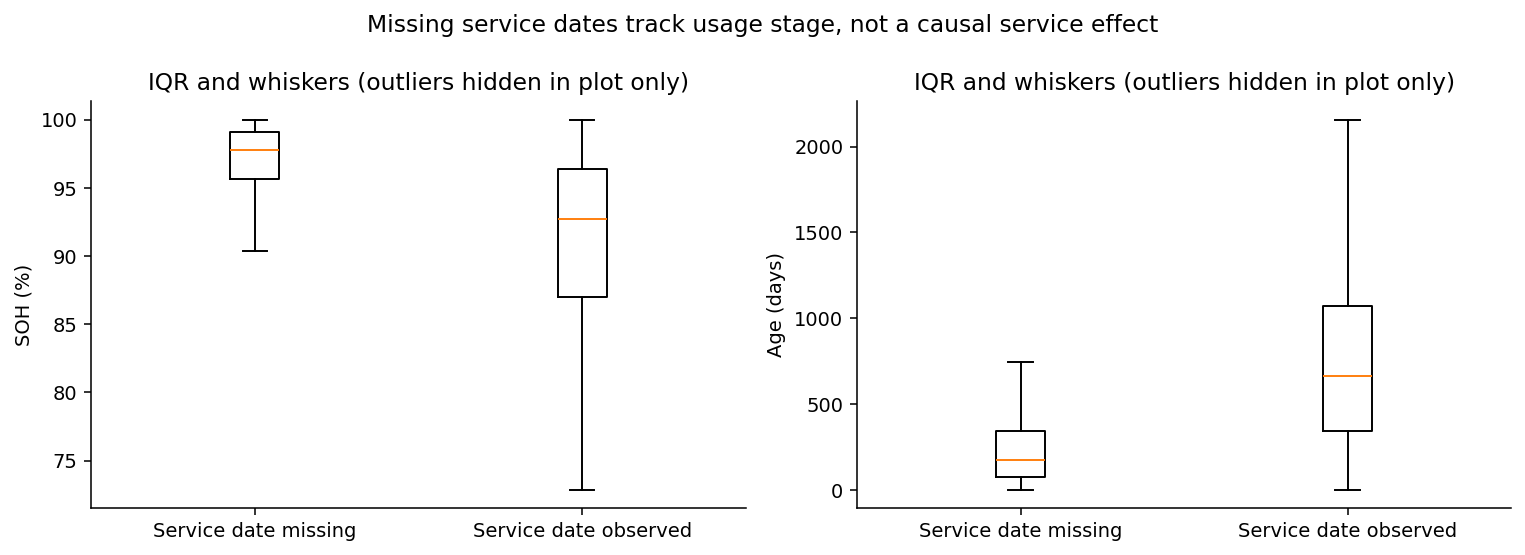

,feature,missing_rows,missing_pct,observed_rows,median_soh_missing,median_soh_observed,median_gap_missing_minus_observed,median_age_missing,median_age_observed
26,last_service_date,13198,37.785,21731,97.79,92.7,5.09,174.0,662.0


In [16]:
show("12_service_missingness_context.png")
display(t["missingness_target_profiles"].query("feature == 'last_service_date'").round(3))

**Temuan:** median SOH saat tanggal servis kosong adalah 97,79%, dibanding 92,70% saat terisi. Median umurnya 174 hari dan 662 hari. Artinya baterai yang masih muda memang belum pernah diservis. Grafik ini tidak menunjukkan bahwa servis menyebabkan degradasi.

## 12. Outlier

Batas 1,5×IQR dipakai untuk menandai kandidat outlier, bukan untuk menghapus data. SOH rendah dan `recall_flag = 1` bisa ikut tertandai hanya karena jarang muncul.

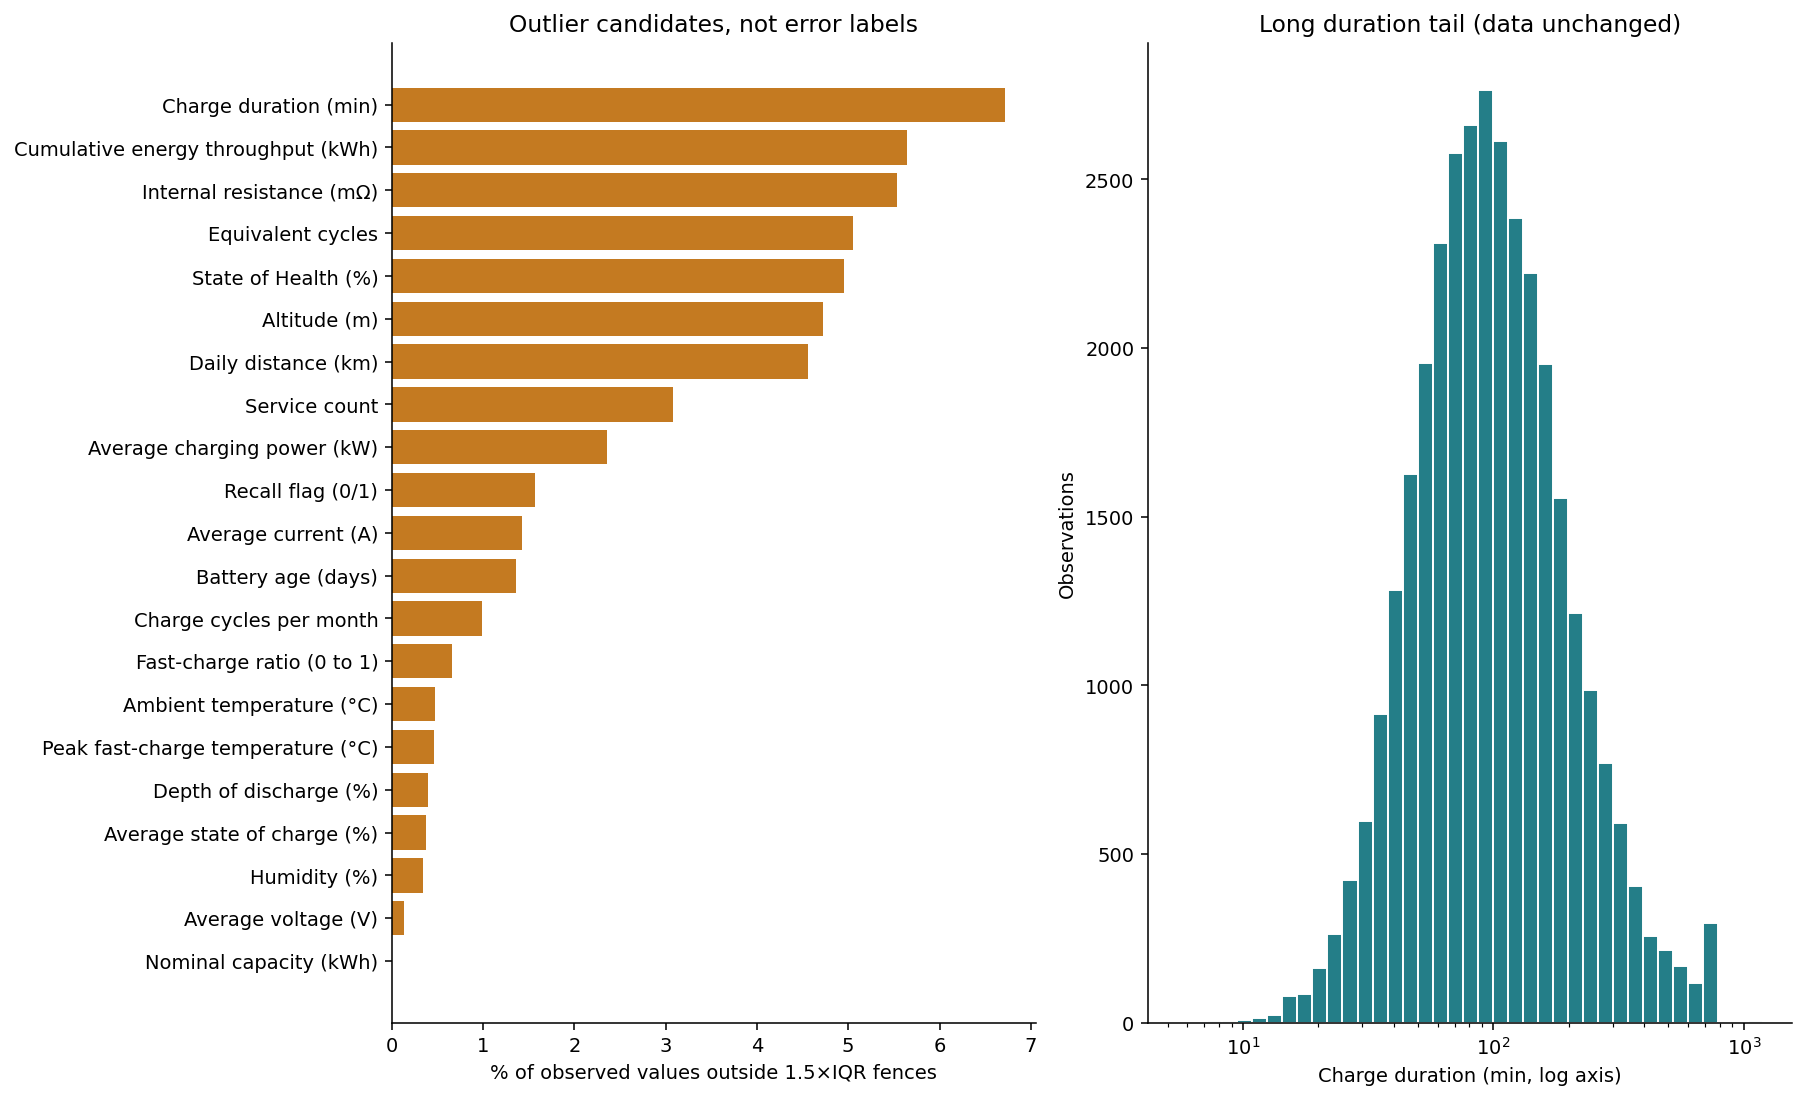

,feature,n,skewness,iqr_low,iqr_high,iqr_flag_n,iqr_flag_pct,median,p99,max
19,charge_time_avg_min,33516,2.807,-76.300,288.500,2252,6.719,94.400,650.170,1190.084
9,total_energy_throughput_kwh,32567,2.178,-57895.150,119884.450,1837,5.641,24155.300,200447.024,402419.900
16,internal_resistance_mohm,33465,2.046,1.515,90.275,1852,5.534,42.920,128.471,307.090
2,cycle_count,33337,1.918,-860.000,1796.000,1684,5.051,372.000,2802.640,5073.000
20,state_of_health_pct,34929,-1.808,78.125,110.005,1729,4.950,95.230,100.000,100.000
12,altitude_m,33297,1.955,-409.000,911.000,1574,4.727,209.000,1357.040,3214.000
3,avg_daily_distance_km,33444,1.825,-43.950,133.250,1523,4.554,39.300,192.657,400.000
14,service_count,33825,1.619,-3.000,5.000,1043,3.084,1.000,7.000,15.000
4,avg_charging_power_kw,33416,0.997,-15.200,76.000,787,2.355,28.600,85.385,147.772
15,recall_flag,33084,7.795,0.000,0.000,519,1.569,0.000,1.000,1.000


,feature,rows_all,rows_inside_iqr_fences,spearman_all,spearman_inside_iqr_fences,inside_feature_unique_values
0,pack_capacity_kwh,33345,33345,-0.001,-0.001,550
1,battery_age_days,32814,32369,-0.881,-0.877,1829
2,cycle_count,33337,31653,-0.907,-0.895,1781
3,avg_daily_distance_km,33444,31921,-0.169,-0.156,1302
4,avg_charging_power_kw,33416,32629,0.002,0.000,1179
5,fast_charge_ratio,32563,32347,-0.003,-0.003,771
6,avg_depth_of_discharge_pct,32933,32803,-0.021,-0.021,785
7,avg_state_of_charge_pct,32778,32657,0.019,0.018,550
8,charge_cycles_per_month,33503,33172,-0.244,-0.239,454
9,total_energy_throughput_kwh,32567,30730,-0.886,-0.870,29963


In [17]:
show("13_outliers_and_tail.png", 1100)
display(t["tails_and_iqr"].sort_values("iqr_flag_pct", ascending=False).round(3))
display(t["outlier_association_sensitivity"].round(3))

**Temuan:** durasi pengisian memiliki ekor sangat panjang (p99 sekitar 650 menit, maksimum sekitar 1.190 menit).

**Sensitivitas:** hubungan kuat umur, siklus, dan energi dengan SOH tetap terlihat walaupun hanya data di dalam batas IQR yang dipakai. Jadi pola utama tidak ditentukan oleh outlier. Untuk `recall_flag`, batas IQR hanya menyisakan nilai 0 sehingga korelasinya tidak terdefinisi. Ini contoh mengapa satu aturan outlier tidak cocok untuk semua fitur.

## 13. Lintasan SOH per baterai

Contoh dipilih tanpa melihat target: tiga ID pertama (urut alfabet) per kimia yang memiliki minimal 10 tanggal valid.

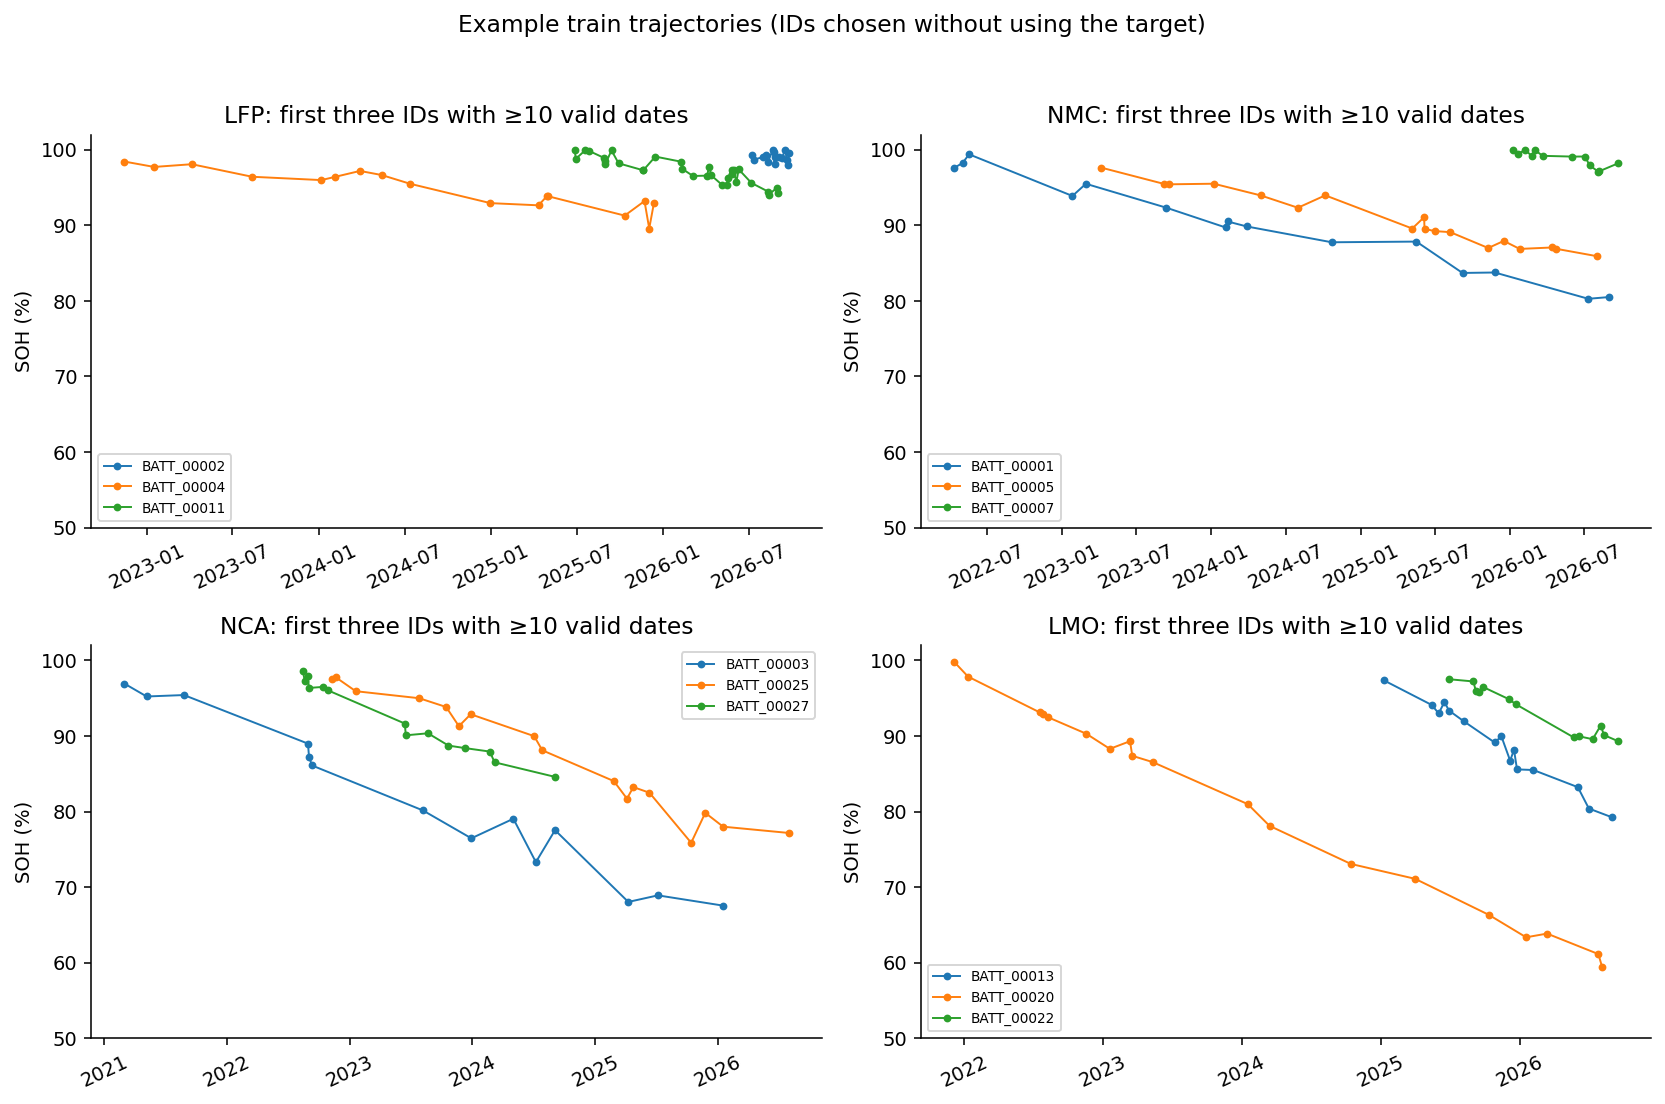

In [18]:
show("14_battery_trajectories.png", 1150)

**Interpretasi:** SOH tidak selalu turun dengan mulus. Ada kenaikan dan osilasi antarobservasi, yang kemungkinan berasal dari noise simulator, bukan pemulihan baterai secara fisik.

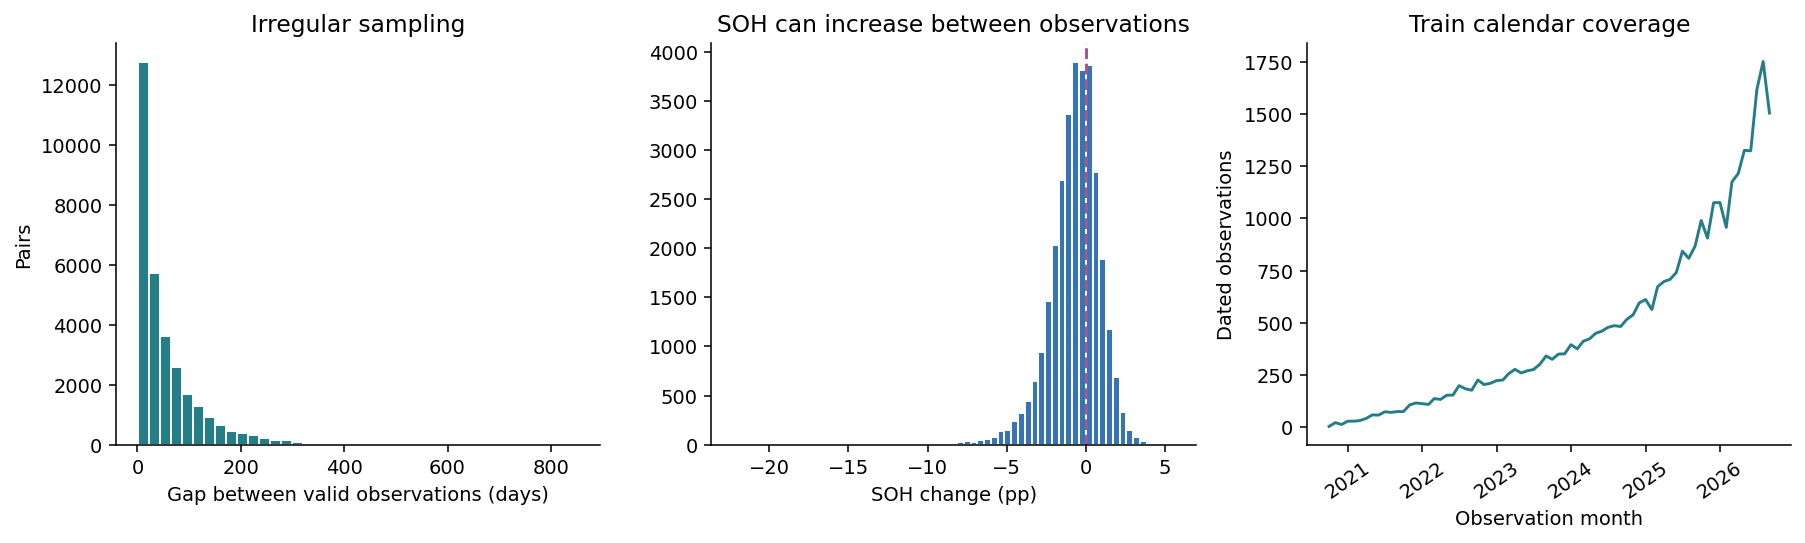

,label,rows,pct_pairs
0,down >0.01 pp,20498,65.015
1,stable ±0.01 pp,670,2.125
2,up >0.01 pp,10360,32.860


,count,mean,std,min,1%,50%,99%,max
gap_days,31528.0,57.753,72.089,1.00,1.000,32.00,345.460,853.00
delta_soh_pp,31528.0,-0.700,1.626,-22.26,-5.737,-0.53,2.490,5.55
delta_cycles,28749.0,59.361,112.174,-634.00,-150.520,29.00,487.000,1463.00
delta_energy_kwh,27395.0,4011.997,8554.773,-64595.00,-13846.630,1924.50,35411.764,131941.90


In [19]:
show("15_temporal_quality.png", 1150)
display(t["temporal_soh_changes"].round(3))
pairs = t["temporal_pairs"]
display(
    pairs[["gap_days", "delta_soh_pp", "delta_cycles", "delta_energy_kwh"]]
    .describe(percentiles=[0.01, 0.5, 0.99])
    .T.round(3)
)
assert pairs.gap_days.gt(0).all()
assert t["temporal_soh_changes"].rows.sum() == len(pairs)

Perubahan SOH dibulatkan ke presisi sumber (0,01 poin) sebelum diklasifikasikan naik, stabil, atau turun.

**Temuan:** dari 31.528 pasangan observasi bertanggal valid, SOH naik lebih dari 0,01 poin pada 10.360 pasangan (32,86%). Jarak antarobservasi juga tidak seragam.

**Implikasi:** bersama counter kumulatif yang kadang turun, temuan ini menjadi alasan input timesteps tidak dipakai. Split per baterai tetap menguji generalisasi ke baterai baru.

## 14. Target alternatif

Label lain di dataset dieksplorasi untuk konteks saja. Tugas tetap regresi SOH, dan label ini tidak boleh menjadi input.

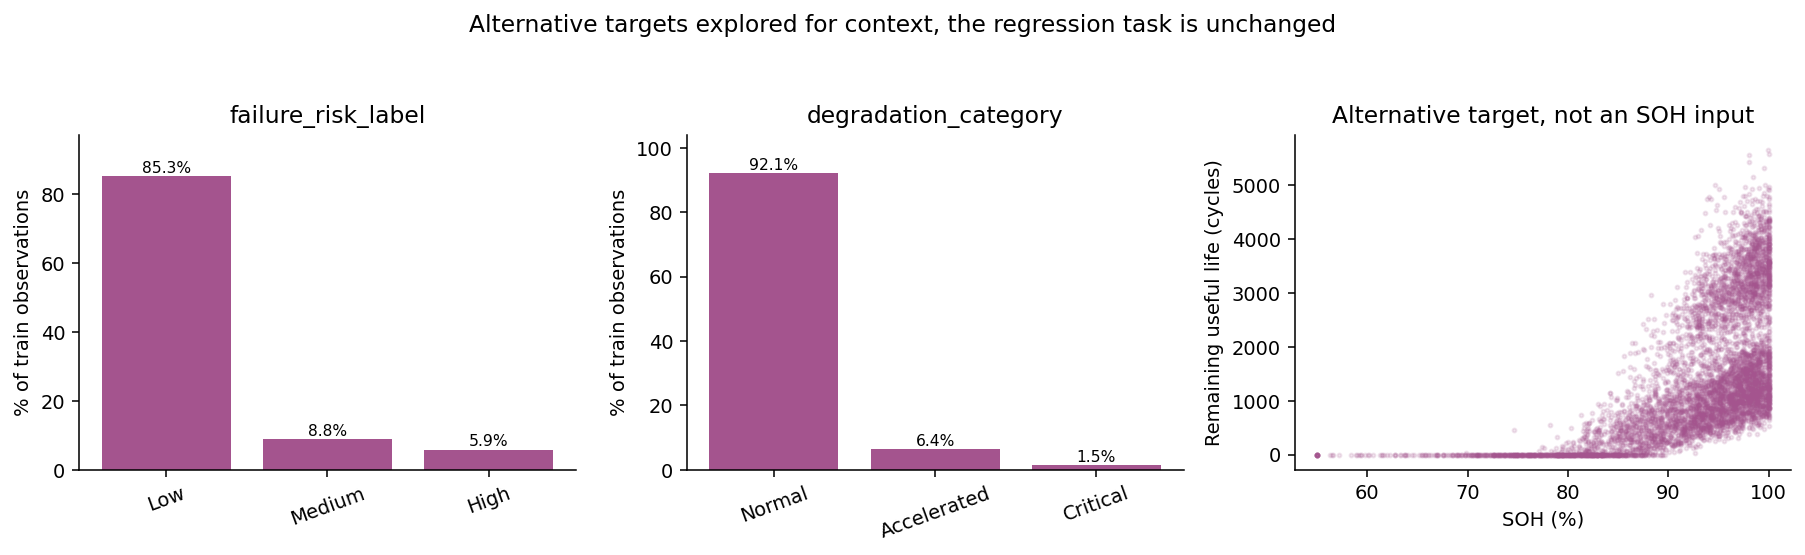

,feature,category,rows,batteries,row_pct,median_soh
38,failure_risk_label,High,2061,403,5.901,74.52
39,failure_risk_label,Low,29781,1820,85.262,96.22
40,failure_risk_label,Medium,3087,758,8.838,83.52
41,degradation_category,Accelerated,2225,494,6.370,77.76
42,degradation_category,Critical,525,128,1.503,65.27
43,degradation_category,Normal,32179,1820,92.127,95.77


In [20]:
show("17_alternative_targets.png", 1150)
display(
    categorical.loc[
        categorical.feature.isin(["failure_risk_label", "degradation_category"]),
        ["feature", "category", "rows", "batteries", "row_pct", "median_soh"],
    ].round(3)
)
forbidden = {
    "capacity_fade_pct",
    "remaining_useful_life_cycles",
    "failure_risk_label",
    "degradation_category",
    TARGET,
}
assert not forbidden.intersection(contract["primary_features"])

**Temuan:** distribusi failure risk di train adalah sekitar 85,26% Low, 8,84% Medium, dan 5,90% High. Degradation category didominasi Normal (92,13%).

Ketiga target alternatif tetap dikeluarkan dari input. `capacity_fade_pct` sama dengan `100 - SOH`, sehingga memakainya akan membuat hasil evaluasi menyesatkan.

## 15. Ringkasan dan implikasi

| Temuan EDA | Implikasi untuk tahap berikutnya |
|---|---|
| Target didominasi SOH tinggi | Laporkan error per rentang SOH dan per baterai |
| Umur, siklus, dan energi kuat dan saling redundan | Uji resep fitur compact (feature selection) |
| Kimia berbeda walaupun umurnya sama | Pertahankan kimia sebagai fitur, MLP dapat menangkap interaksi |
| Missing value tersebar di banyak fitur | Imputasi median dari train plus indikator missing |
| Skala fitur berbeda jauh dan ada ekor panjang | Standardisasi, serta uji log transform dan capping |
| Observasi berulang dan urutan waktu bermasalah | Split per baterai, tanpa timesteps |
| Ada kolom yang membocorkan target | Keluarkan `capacity_fade_pct`, target alternatif, dan proxy sensor |

Kontrak fitur dan split tidak diubah pada notebook ini. Keterbatasan utama: data sintetis, generator tidak tersedia, dan tidak ada mask asli untuk missing value maupun outlier.

## 16. Verifikasi

Sel berikut memastikan analisis hanya memakai train, semua 35 kolom tercakup, dan seluruh gambar berhasil dibuat.

In [21]:
meta = eda["provenance"]
assert meta["scope"] == "train only"
assert meta["train_rows"] == 34929 and meta["train_batteries"] == 1820
manifest = pd.read_csv(ROOT / "data/splits/battery_split.csv")
train_ids = set(manifest.loc[manifest.split.eq("train"), "battery_id"])
assert set(train.battery_id) == train_ids
assert set(t["battery_profiles"].index) == train_ids
assert set(t["temporal_pairs"].battery_id).issubset(train_ids)
assert set(t["battery_age_means"].battery_id).issubset(train_ids)
assert set(t["column_coverage"]["column"]) == set(train.columns)
assert (
    meta["dataset_sha256"]
    == hashlib.sha256((ROOT / "data/raw/ev_battery_health.csv").read_bytes()).hexdigest()
)
assert (
    meta["split_manifest_sha256"]
    == hashlib.sha256((ROOT / "data/splits/battery_split.csv").read_bytes()).hexdigest()
)
assert (
    meta["feature_contract_sha256"]
    == hashlib.sha256((ROOT / "configs/feature_contract.json").read_bytes()).hexdigest()
)
assert len(eda["figures"]) == 18
assert all((eda["output"] / name).is_file() for name in eda["figures"])
assert all((eda["output"] / name).is_file() for name in eda["figures"])
print("PASS: train saja, cakupan 35 kolom, bobot/denominator benar, input asli utuh, 18 grafik PNG tersedia.")
display(pd.Series(meta["packages"], name="versi").to_frame())

PASS: train saja, cakupan 35 kolom, bobot/denominator benar, input asli utuh, 18 grafik PNG tersedia.


,versi
numpy,2.2.5
pandas,2.3.2
matplotlib,3.10.6
scipy,1.16.1
nbformat,5.10.4
nbclient,0.10.2


**Artefak:**

- `results/eda/EDA_REPORT.md`: laporan lengkap.
- `results/eda/*.csv`: tabel pendukung.
- `results/eda/eda_provenance.json`: hash data dan versi lingkungan.

Reproduksi dari root proyek:

```bash
python -m ev_battery eda
python scripts/run_notebook.py notebooks/01_eda.ipynb
```

**Berikutnya:** `02_preprocessing.ipynb` membangun pipeline preprocessing berdasarkan temuan di atas.